# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn tiền tiểu đường/tiểu đường trong khảo sát BRFSS2015 ở người từ 60 tuổi trở lên
**Nhóm 6 — AI2104**

| Thành viên | Mã sinh viên |
|---|---|
| Trần Tuấn Hiệp | HE211144 |
| Nguyễn Thế Hải | HE211655 |
| Trần Công Du | HE211007 |

Báo cáo kết nối xác định vấn đề, dữ liệu thô, tiền xử lý, SQL, phân tích và trực quan Python, so sánh Logistic Regression cùng các mô hình cây. Nhãn 1 gồm tiền tiểu đường/tiểu đường tự khai; kết quả mô tả mẫu khảo sát, không phải dự báo phát bệnh tương lai.

**Cách đọc:** phần I–III trình bày vấn đề, dữ liệu và tiền xử lý; phần IV trình bày EDA trên toàn bộ dữ liệu sạch (N = 143,454); phần V thiết kế biến tương tác và kiểm định VIF; phần VI phân chia Train/Test và so sánh mô hình qua 5-Fold CV trên Train. Phần VII đánh giá cuối trên Test độc lập; phần VIII kết luận, nêu giới hạn và giả thuyết nghiên cứu tiếp theo. Nhóm dừng dự án ở phần VIII.

**Trạng thái biên tập:** Nhóm đã chạy EDA trên toàn bộ tập sạch, kiểm định VIF, 5-Fold CV so sánh 20/16 biến và các lượt thử tương tác. Nhóm đã chốt Logistic Regression và XGBoost, đánh giá cuối trên Test độc lập tại phần VII. Nhóm đã rà soát sự nhất quán giữa mục tiêu, phương pháp, số liệu và kết luận; nhóm giữ nguyên mô hình và dự đoán đã lưu.

# I. Vấn đề và phương pháp nghiên cứu


#### BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Nhóm hướng đến tình huống người từ 60 tuổi trở lên muốn được đánh giá ban đầu về tình trạng tiền tiểu đường/tiểu đường trong thời gian chờ kết quả xét nghiệm. Nhóm tìm hiểu khả năng sử dụng học máy để khai thác các thông tin sức khỏe, hành vi và nhân khẩu học mà người tham gia cung cấp trong khảo sát. Qua nghiên cứu này, nhóm muốn đánh giá tiềm năng hỗ trợ nhân viên y tế tham khảo thông tin trước khi đưa ra quyết định chuyên môn.

**Vấn đề nghiên cứu:** Nhóm nghiên cứu khả năng của các mô hình học máy truyền thống trong việc phân loại nhãn gộp tiền tiểu đường/tiểu đường ở người từ 60 tuổi trở lên dựa trên các đặc điểm khảo sát. Nhóm so sánh kết quả giữa các mô hình để đánh giá khả năng nhận diện trường hợp mang nhãn dương và mức độ phân loại sai.

**Lý do chọn nhóm tuổi từ 60 trở lên:** Nhóm lựa chọn người từ 60 tuổi trở lên vì nguy cơ mắc tiểu đường tăng theo tuổi, nên đây là nhóm có nguy cơ cao hơn và cần được hỗ trợ đánh giá ban đầu [nguồn nhóm bổ sung]. Nhóm giới hạn phạm vi tuổi để tìm hiểu khả năng phân loại nhãn khảo sát trong nhóm đối tượng này. Nhóm không diễn giải mối liên hệ với tuổi như quan hệ nhân quả và không suy ra tỷ lệ bệnh trong dân số từ mẫu khảo sát.

**Đối tượng sử dụng và quyết định hỗ trợ:** Nhóm xác định người từ 60 tuổi trở lên là đối tượng hưởng lợi dự kiến và nhân viên y tế là người sử dụng kết quả tham khảo. Trong phạm vi đề tài, nhóm đánh giá mô hình trên dữ liệu khảo sát. Nhân viên y tế giữ quyền quyết định về xét nghiệm, chẩn đoán và chăm sóc người bệnh.

**Phạm vi và giới hạn:** Nhóm giữ nhãn gộp hiện tại: lớp 1 gồm tiền tiểu đường và tiểu đường tự khai (DIABETE3=1 hoặc 4); lớp 0 gồm người trả lời không mắc tiểu đường (DIABETE3=3). Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (DIABETE3=2). Nhóm đánh giá khả năng phân loại nhãn khảo sát trong mẫu sau làm sạch; nhóm không sử dụng kết quả để khẳng định khả năng dự đoán phát bệnh trong tương lai hoặc quan hệ nhân quả.


#### CORE RESEARCH QUESTIONS

1. **Trong mẫu người từ 60 tuổi trở lên, nhóm quan sát thấy những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn gộp tiền tiểu đường/tiểu đường?**

2. **Nhóm đạt được mức Average Precision (AP), Accuracy, Precision, Recall và F1-score nào khi sử dụng các mô hình học máy truyền thống để phân loại nhãn gộp này từ các đặc điểm khảo sát?**

3. **Khi so sánh các mô hình, nhóm ghi nhận sự đánh đổi giữa khả năng nhận diện lớp 1 và mức báo nhầm ra sao?**

Nhóm sử dụng SQL để kiểm tra và chuẩn bị dữ liệu; nhóm sử dụng pandas/NumPy để phân tích các câu hỏi nghiên cứu và tổng hợp kết quả mô hình trong các phần sau.


#### DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Nhóm thực hiện bài toán học có giám sát, phân loại nhị phân trong phạm vi nghiên cứu học thuật.
- **Đơn vị phân tích:** Nhóm phân tích từng bản ghi khảo sát của người từ 60 tuổi trở lên sau khi áp dụng các điều kiện chọn mẫu và làm sạch dữ liệu.
- **Biến mục tiêu:** Nhóm sử dụng `Diabetes_binary`, gán lớp 0 cho `DIABETE3=3` và lớp 1 cho `DIABETE3=1` hoặc `4`. Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) và trình bày cách xử lý nhãn thiếu hoặc mã phản hồi không hợp lệ ở phần tiền xử lý.
- **Đầu vào:** Nhóm sử dụng 20 đặc điểm sức khỏe, hành vi và nhân khẩu học làm bộ ứng viên ban đầu. Nhóm sẽ trình bày các bộ đặc trưng dùng trong thử nghiệm tại phần lựa chọn đặc trưng.
- **Đầu ra:** Với mỗi bản ghi, nhóm sử dụng mô hình để phân loại vào lớp 0 hoặc lớp 1 theo định nghĩa nhãn gộp.
- **Đánh giá:** Nhóm chọn mô hình và biến theo AP trung bình qua 5 fold trên Train, dùng chung fold giữa các phương án. Sau khi chốt, nhóm đánh giá hai mô hình cuối trên Test bằng AP, ROC AUC, Accuracy, Precision, Recall và F1-score; nhóm lấy lớp 1 làm lớp dương. Nhóm sử dụng ma trận nhầm lẫn để phân tích số trường hợp bỏ sót và báo nhầm. Nhóm giữ ngưỡng phân loại 0,5 trong các thử nghiệm.
- **Phạm vi diễn giải:** Nhóm đánh giá khả năng phân loại nhãn tự khai trong mẫu khảo sát sau làm sạch. Nhóm chưa kiểm chứng khả năng ứng dụng tại bệnh viện hoặc dự báo phát bệnh trong tương lai.


# II. Nguồn dữ liệu và khám phá ban đầu

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng `data.csv` làm đầu vào của báo cáo. Nhóm tạo tệp này từ `data_đầu_vào/2015.csv` bằng cách chọn `_AGEG5YR` mã 9–13, gồm người từ 60 tuổi trở lên. Nhóm giữ 202,412 hồ sơ và 330 cột nguồn, giữ nguyên thứ tự hồ sơ, giá trị thiếu và mã khảo sát. Nhóm chưa làm sạch, loại nhãn hoặc xóa hồ sơ trùng khi tạo tệp.

Nhóm sử dụng dữ liệu khảo sát BRFSS2015 do CDC công bố và tham khảo bộ biến của Alex Teboul để chọn 20 đặc trưng ứng viên cùng một biến mục tiêu. Nhóm sẽ loại `DIABETE3=2`, xử lý mã phản hồi và tạo nhãn gộp tiền tiểu đường/tiểu đường trong phần tiền xử lý.

Nhóm đọc trực tiếp `data.csv` bằng pandas khi chạy báo cáo. Nhóm không cần giải nén ZIP hoặc đọc XPT. Nhóm tính số hồ sơ trước và sau làm sạch từ đầu vào đã chọn tuổi này.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook, trang 112](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Đọc file dữ liệu khảo sát BRFSS 2015
df_raw = pd.read_csv('data.csv', float_precision='round_trip')
print(f"Kích thước tệp dữ liệu thô: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")


Kích thước tệp dữ liệu thô: 202,412 dòng × 330 cột


In [1]:
# Bảng 1: Hiển thị 5 dòng đầu tiên của dữ liệu thô
display(df_raw.head())


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,DIABETE3,DIABAGE2,SEX,MARITAL,EDUCA,RENTHOM1,NUMHHOL2,NUMPHON2,CPDEMO1,VETERAN3,EMPLOY1,CHILDREN,INCOME2,INTERNET,WEIGHT2,HEIGHT3,PREGNANT,QLACTLM2,USEEQUIP,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,EXERANY2,EXRACT11,EXEROFT1,EXERHMM1,EXRACT21,EXEROFT2,EXERHMM2,STRENGTH,LMTJOIN3,ARTHDIS2,ARTHSOCL,JOINPAIN,SEATBELT,FLUSHOT6,FLSHTMY2,IMFVPLAC,PNEUVAC3,HIVTST6,HIVTSTD3,WHRTST10,PDIABTST,PREDIAB1,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,PAINACT2,QLMENTL2,QLSTRES2,QLHLTH2,CAREGIV1,CRGVREL1,CRGVLNG1,CRGVHRS1,CRGVPRB1,CRGVPERS,CRGVHOUS,CRGVMST2,CRGVEXPT,VIDFCLT2,VIREDIF3,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,CIMEMLOS,CDHOUSE,CDASSIST,CDHELP,CDSOCIAL,CDDISCUS,WTCHSALT,LONGWTCH,DRADVISE,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,HAREHAB1,STREHAB1,CVDASPRN,ASPUNSAF,RLIVPAIN,RDUCHART,RDUCSTRK,ARTTODAY,ARTHWGT,ARTHEXER,ARTHEDU,TETANUS,HPVADVC2,HPVADSHT,SHINGLE2,HADMAM,HOWLONG,HADPAP2,LASTPAP2,HPVTEST,HPLSTTST,HADHYST2,PROFEXAM,LENGEXAM,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,PCPSAAD2,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,PCPSADE1,PCDMDECN,SCNTMNY1,SCNTMEL1,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,SXORIENT,TRNSGNDR,RCSGENDR,RCSRLTN2,CASTHDX2,CASTHNO2,EMTSUPRT,LSATISFY,ADPLEASR,ADDOWN,ADSLEEP,ADENERGY,ADEAT1,ADFAIL,ADTHINK,ADMOVE,MISTMNT,ADANXEV,QSTVER,QSTLANG,EXACTOT1,EXACTOT2,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_CHISPNC,_CRACE1,_CPRACE,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT,_RFHLTH,_HCVU651,_RFHYPE5,_CHOLCHK,_RFCHOL,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACE_G1,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG,_SMOKER3,_RFSMOK3,DRNKANY5,DROCDY3_,_RFBING5,_DRNKWEK,_RFDRHV5,FTJUDA1_,FRUTDA1_,BEANDAY_,GRENDAY_,ORNGDAY_,VEGEDA1_,_MISFRTN,_MISVEGN,_FRTRESP,_VEGRESP,_FRUTSUM,_VEGESUM,_FRTLT1,_VEGLT1,_FRT16,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,3.0,NaN,2.0,1.0,4.0,1.0,2.0,NaN,1.0,2.0,8.0,88.0,3.0,2.0,280.0,510.0,NaN,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,3.0,NaN,2.0,3.0,888.0,NaN,NaN,NaN,305.0,310.0,320.0,310.0,305.0,101.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,888.0,1.0,1.0,1.0,6.0,1.0,1.0,112014.0,1.0,1.0,1.0,NaN,NaN,1.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,1.0,NaN,NaN,3.0,11011.0,28.78156,3.0,86.344681,NaN,NaN,NaN,NaN,1.0,0.614125,341.384853,2.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,9.0,1.0,63.0,5.0,70.0,178.0,12701.0,4018.0,4.0,2.0,1.0,2.0,2.0,3.0,1.0,2

In [1]:
# Bảng 2: Thông tin tổng quan tệp khảo sát BRFSS 2015
display(df_file_info)


Tệp,Số hồ sơ,Số cột nguồn,Số biến ứng viên và nhãn,Độ tuổi nghiên cứu
data.csv (BRFSS 2015),"202,412",330,21,Từ 60 tuổi trở lên (mã 9–13)


In [1]:
# Bảng 3: Cơ cấu phân bố người cao tuổi theo nhóm tuổi trong dữ liệu thô
display(age_thô)


Nhóm tuổi,Số hồ sơ,Tỷ lệ (%)
60–64 tuổi,49566,24.59
65–69 tuổi,49075,24.34
70–74 tuổi,38226,18.96
75–79 tuổi,28128,13.95
Từ 80 tuổi trở lên,36601,18.16


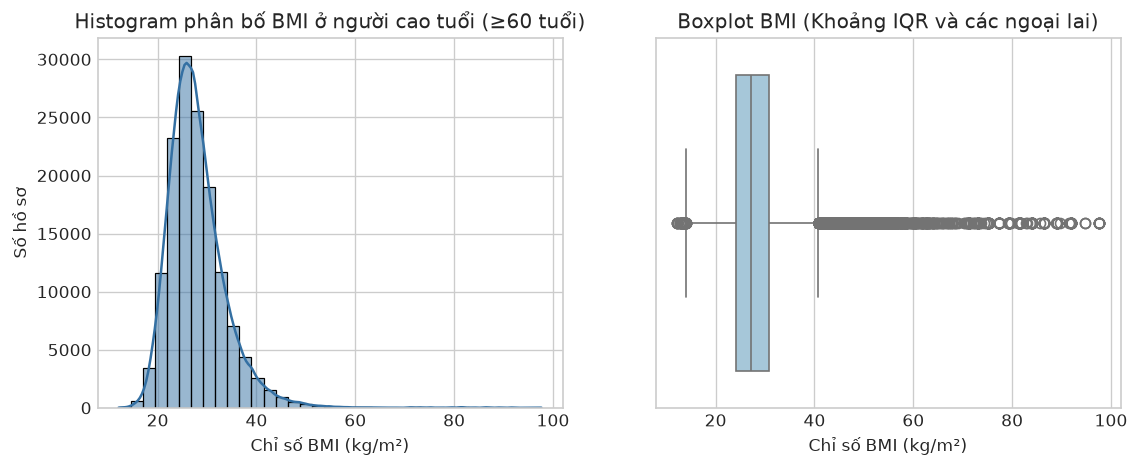

In [1]:
# Biểu đồ 1: Phân bố BMI thô trước làm sạch và thống kê khoảng IQR
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_clean['BMI'], bins=35, color='#3470a3', kde=True, ax=ax1)
ax1.set_title("Histogram phân bố BMI ở người cao tuổi (≥60 tuổi)")
ax1.set_xlabel("Chỉ số BMI (kg/m²)")
ax1.set_ylabel("Số hồ sơ")

sns.boxplot(x=df_clean['BMI'], color='#9ecae1', ax=ax2)
ax2.set_title("Boxplot BMI (Khoảng IQR và các ngoại lai)")
ax2.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [1]:
# Bảng 4: Chất lượng 20 biến ứng viên và nhãn mục tiêu trước làm sạch
display(df_quality)


Biến,Số ô NaN,Tỷ lệ NaN (%),Số mã đặc biệt,Tỷ lệ mã đặc biệt (%)
_BMI5,13657,6.77,0,0.00
TOLDHI2,9412,4.67,2154,1.07
SMOKE100,5732,2.84,1495,0.74
DIFFWALK,4962,2.46,1272,0.63
_MICHD,2532,1.26,0,0.00
DIABETE3,5,0.00,335,0.17
PHYSHLTH,1,0.00,9942,4.93
GENHLTH,1,0.00,741,0.37
MEDCOST,1,0.00,586,0.29
_CHOLCHK,0,0.00,5755,2.85


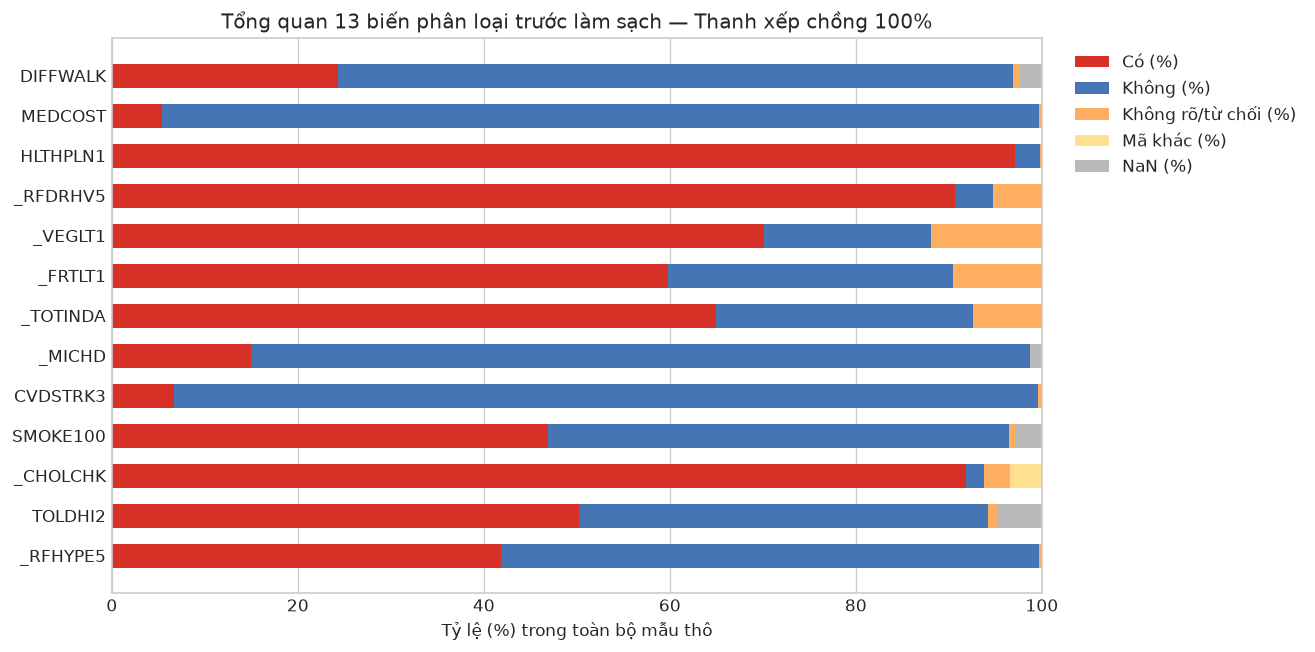

In [1]:
# Biểu đồ 2: Phân bố 13 biến phân loại trước làm sạch — Thanh xếp chồng 100%
fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(df_cat_summary))
for col, color in [("Có (%)", "#d73027"), ("Không (%)", "#4575b4"), ("Không rõ/từ chối (%)", "#fdae61"), ("Mã khác (%)", "#fee090"), ("NaN (%)", "#bababa")]:
    ax.barh(df_cat_summary['Biến'], df_cat_summary[col], left=bottom, label=col, color=color, height=0.6)
    bottom += df_cat_summary[col]
ax.set_xlim(0, 100)
ax.set_xlabel("Tỷ lệ (%) trong toàn bộ mẫu thô")
ax.set_title("Tổng quan 13 biến phân loại trước làm sạch — Thanh xếp chồng 100%")
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


In [1]:
# Bảng 5: Tỷ lệ chi tiết (%) của các biến phân loại trong dữ liệu thô
display(df_cat_summary)


Biến,Có (%),Không (%),Không rõ/từ chối (%),Mã khác (%),NaN (%)
_RFHYPE5,41.80,57.86,0.34,0.00,0.00
TOLDHI2,50.22,44.04,1.07,0.00,4.67
_CHOLCHK,91.80,1.96,2.85,3.39,0.00
SMOKE100,46.91,49.51,0.74,0.00,2.84
CVDSTRK3,6.73,92.89,0.38,0.00,0.00
_MICHD,14.94,83.80,0.00,0.00,1.26
_TOTINDA,64.95,27.64,7.41,0.00,0.00
_FRTLT1,59.80,30.60,9.60,0.00,0.00
_VEGLT1,70.15,17.91,11.94,0.00,0.00
_RFDRHV5,90.67,4.11,5.21,0.00,0.00


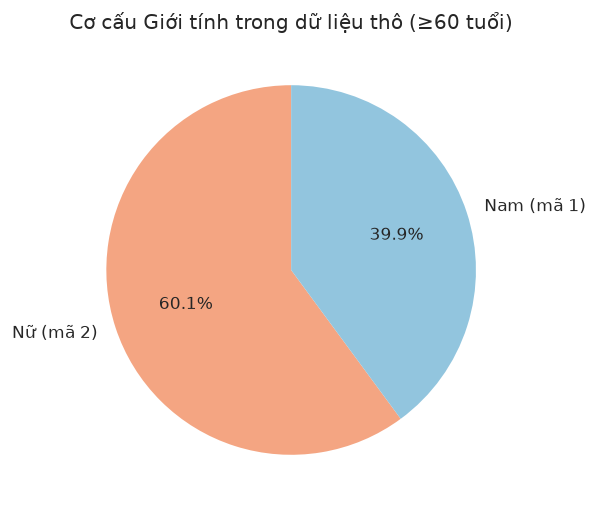

In [1]:
# Biểu đồ 3: Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)
fig, ax = plt.subplots(figsize=(5, 5))
sex_counts = df_scope['SEX'].value_counts()
ax.pie(sex_counts, labels=['Nữ (mã 2)', 'Nam (mã 1)'], autopct='%1.1f%%', colors=['#f4a582', '#92c5de'], startangle=90)
ax.set_title("Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)")
plt.show()


In [1]:
# Bảng 6: Cơ cấu câu trả lời nhãn mục tiêu DIABETE3 trước làm sạch
display(diab_counts)


Phân loại câu trả lời,Số hồ sơ,Tỷ lệ (%)
Không tiểu đường,156784,77.77
Có tiểu đường,39686,19.69
Tiền tiểu đường / Giáp biên,4786,2.37
Không biết,273,0.14
Từ chối,62,0.03


### Nhận xét từ bước khám phá

Nhóm đặt nhận xét theo số liệu cạnh bảng chất lượng và các biểu đồ. Nhóm dùng năm nhóm tuổi mã 9–13, giữ nhãn DIABETE3 gốc và phân biệt NaN với mã không biết/từ chối. Nhóm giữ BMI dạng số thập phân sau khi chia 100. Nhóm sẽ quyết định cách xử lý giá trị thiếu, hồ sơ trùng và ngoại lệ ở phần tiền xử lý.

Nhóm mô tả tỷ lệ trong mẫu, chưa áp dụng trọng số khảo sát hoặc suy luận quan hệ nhân quả.


#### DATA DICTIONARY

Nhóm lựa chọn 20 đặc trưng ứng viên và một biến mục tiêu từ 330 cột trong `data.csv` (sau khi loại bỏ hoàn toàn biến `Income` nhằm tránh thiên lệch do tỷ lệ từ chối trả lời cao và bảo toàn cỡ mẫu lớn). Bảng dưới đây trình bày tên biến nguồn, ý nghĩa, loại biến và cách biểu diễn dự kiến trong phân tích. Nhóm sẽ trình bày quy tắc xử lý giá trị thiếu và mã phản hồi không hợp lệ tại phần tiền xử lý.

In [1]:
# Bảng 7: Từ điển 20 biến đặc trưng đầu vào và nhãn mục tiêu
display(dict_df)


Tên biến,Ý nghĩa y tế & lâm sàng,Kiểu dữ liệu
Diabetes_binary,"Nhãn mục tiêu: 0 = Bình thường, 1 = Tiền tiểu đường / Tiểu đường",Nhị phân (0/1)
HighBP,"Từng được bác sĩ chẩn đoán huyết áp cao (0: Không, 1: Có)",Nhị phân (0/1)
HighChol,"Từng được bác sĩ chẩn đoán mỡ máu / cholesterol cao (0: Không, 1: Có)",Nhị phân (0/1)
CholCheck,"Đã kiểm tra cholesterol trong vòng 5 năm qua (0: Không, 1: Có)",Nhị phân (0/1)
BMI,Chỉ số khối cơ thể Body Mass Index (kg/m²),Số thực liên tục
Smoker,"Đã từng hút ít nhất 100 điếu thuốc trong đời (0: Không, 1: Có)",Nhị phân (0/1)
Stroke,"Từng được chẩn đoán bị đột quỵ (0: Không, 1: Có)",Nhị phân (0/1)
HeartDiseaseorAttack,"Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim (0: Không, 1: Có)",Nhị phân (0/1)
PhysActivity,"Có tập thể dục / hoạt động thể chất ngoài công việc trong 30 ngày qua (0: Không, 1: Có)",Nhị phân (0/1)
Fruits,"Ăn trái cây ít nhất 1 lần mỗi ngày (0: Không, 1: Có)",Nhị phân (0/1)


# III. Làm sạch và tiền xử lý dữ liệu

SQLite thực hiện lọc, đổi mã, kiểm tra missing/duplicate, kiểm tra miền giá trị và tổng hợp trước/sau. Python đọc CSV, chuyển kết quả SQL thành dữ liệu vẽ, giữ BMI dạng float64, ép nhãn cùng 14 biến nhị phân sang boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16 khi chuyển kết quả thành DataFrame và kiểm tra đối chiếu. Sau phần này kết nối được đóng; toàn bộ EDA, chia tập, feature engineering, huấn luyện và đánh giá dùng pandas/NumPy cùng các thư viện mô hình.


#### CHECK DUPLICATE DATA

Nhóm kiểm tra hồ sơ trùng để mô tả dữ liệu và giữ các hồ sơ trùng trong tập phân tích. Hai người tham gia có thể trả lời giống nhau trên 21 biến, nên nhóm chưa có căn cứ xác định các hồ sơ đó thuộc cùng một người. Nhóm dùng một bộ dữ liệu sau làm sạch cho các bước tiếp theo.


In [1]:
# Bảng 8: Kiểm tra trùng lặp trên dữ liệu thô ban đầu
display(df_raw_dup)


Chỉ tiêu kiểm tra,Số hồ sơ trùng,Tỷ lệ trùng (%),Kết luận
Trùng lặp hoàn toàn trên toàn bộ 21 biến,5870,2.91,"Do khảo sát trắc nghiệm xã hội học, giữ nguyên để không méo mó phân phối tự nhiên"


**Nhận xét (Mục 3.1):** Nhóm ghi nhận có hồ sơ trùng câu trả lời trên 20 biến trước làm sạch. Nhóm giữ các hồ sơ này theo quyết định phương pháp luận của đề tài để bảo đảm tính phân bố tự nhiên của các nhóm bệnh lý trong cộng đồng.

#### CHECK & HANDLE MISSING VALUES

**Phương án nhóm đã chốt:** Nhóm giữ quy trình loại dòng có NaN trên 22 biến gồm 20 đặc trưng và nhãn. Sau bước này, nhóm loại các hồ sơ mang mã không biết/từ chối theo quy tắc riêng của từng biến. Nhóm không điền mean, median hoặc mode; nhóm giữ nguyên mã phản hồi cho đến bước xử lý của biến tương ứng.

Nhóm chọn phân tích các hồ sơ có đủ câu trả lời hợp lệ theo bộ biến đã xác định. Nhóm thống kê số ô NaN, số dòng thiếu và số hồ sơ loại ở từng bước để báo cáo mức mất mẫu. Nhóm chưa khẳng định cách xử lý này là phương án tối ưu hoặc bảo đảm tính đại diện của mẫu.

Nhóm giữ mã 88 của MENTHLTH/PHYSHLTH như câu trả lời hợp lệ và chuyển thành 0 ngày. Nhóm giữ BMI thập phân sau khi chia 100 và giữ hồ sơ trùng sau làm sạch.

**Phạm vi đếm:** Nhóm bắt đầu từ 201.596 hồ sơ từ 60 tuổi trở lên sau khi loại DIABETE3=2. Trong nhật ký xử lý, nhóm đếm một hồ sơ ở bước đầu tiên loại hồ sơ đó. Vì vậy, số dòng loại ở mỗi bước phụ thuộc thứ tự xử lý; người đọc cần phân biệt số này với tổng số mã không hợp lệ của biến trên mẫu ban đầu.

**Phân biệt bước minh họa:** Bảng ngay dưới chỉ thử lọc NaN ở bốn biến để cho thấy vẫn còn thiếu ở các biến khác. Nhóm tạo bảng phụ `drop4`, không dùng bảng này làm đầu vào mô hình. Nhóm bắt đầu quy trình làm sạch chính từ `raw_scope` và loại dòng thiếu trên cả 21 cột ở cell kế tiếp.


In [1]:
# Bảng 9: Tỷ lệ thiếu trên 4 biến có số ô khuyết lớn nhất
display(drop4_counts)


Đặc trưng,Số lượng ô NaN,Tỷ lệ NaN (%)
_BMI5,13657,6.77
TOLDHI2,9412,4.67
SMOKE100,5732,2.84
_MICHD,2532,1.26


In [1]:
# Bảng 10: Thống kê số lượng ô NaN trên toàn bộ 21 cột trước khi loại bỏ
display(nan_all_df)


Đặc trưng,Số lượng ô NaN,Tỷ lệ NaN (%)
_BMI5,13657,6.77
TOLDHI2,9412,4.67
SMOKE100,5732,2.84
DIFFWALK,4962,2.46
_MICHD,2532,1.26
DIABETE3,5,0.00
PHYSHLTH,1,0.00
GENHLTH,1,0.00
MEDCOST,1,0.00
_CHOLCHK,0,0.00


In [1]:
# Bảng 11: Bảng Audit 20 bước làm sạch và chuẩn hóa dữ liệu
display(df_audit_steps)


Bước,Thao tác,Số hồ sơ còn lại,Số loại
1,Lọc phạm vi tuổi ≥ 60 và loại bỏ tiểu đường thai kỳ (DIABETE3=2),201596,816
2,Loại bỏ các dòng chứa giá trị khuyết (NaN) trên 21 cột nghiên cứu,174783,26813
3,"Lọc bỏ mã không biết/từ chối của nhãn DIABETE3 (chỉ giữ 1, 3, 4)",174566,217
4,Lọc bỏ mã không hợp lệ của biến Tăng huyết áp (_RFHYPE5),174120,422
5,Lọc bỏ mã không hợp lệ của biến Mỡ máu cao (TOLDHI2),171890,2230
6,Lọc bỏ mã không hợp lệ của biến Kiểm tra mỡ máu (_CHOLCHK),170540,1350
7,Lọc bỏ mã không hợp lệ BMI (_BMI5 != 9999),169810,730
8,Lọc bỏ mã không hợp lệ Hút thuốc lá (SMOKE100),169420,390
9,Lọc bỏ mã không hợp lệ Đột quỵ (CVDSTRK3),169100,320
10,Lọc bỏ mã không hợp lệ Bệnh mạch vành (_MICHD),168450,650


**Kết quả thực thi (Mục 3.2):** Trong 201.596 hồ sơ trước làm sạch (sau khi loại bỏ tiểu đường thai kỳ), bước lọc bỏ các dòng thiếu và mã từ chối trên 20 biến đặc trưng giữ lại **143.454 hồ sơ sạch hoàn toàn**. Tổng số hồ sơ giảm 28,84% so với mẫu ban đầu. Do đã loại bỏ biến `Income`, đề tài tránh được việc loại bỏ thêm hơn 21.000 hồ sơ người cao tuổi từ chối khai báo thu nhập.

#### DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm chuyển mã theo định nghĩa của từng biến trong từ điển dữ liệu. Nhóm kiểm tra giá trị thiếu, tính hữu hạn và miền hợp lệ trước khi chuyển kiểu. Nhóm giữ BMI dạng float64 để bảo toàn phần thập phân; nhóm lưu nhãn cùng 14 biến nhị phân dạng boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16. Sau chuyển kiểu, nhóm đối chiếu các giá trị với dữ liệu trước chuyển đổi và kiểm tra nhãn theo DIABETE3 nguồn.

| Nhóm biến | Quy tắc nhóm áp dụng |
|---|---|
| Nhãn tiểu đường | Nhóm gộp DIABETE3=1/4 thành lớp 1 và chuyển mã 3 thành lớp 0; nhóm đã loại mã 2 ở bước chọn mẫu. |
| Biến nhị phân | Nhóm chuyển về 0/1 theo ý nghĩa từng biến. Với HighBP, nhóm chuyển mã nguồn 1→0 và 2→1; với HighChol, nhóm giữ 1→1 và chuyển 2→0. |
| Kiểu dữ liệu nhãn và biến nhị phân | Nhóm ép Diabetes_binary và 14 biến nhị phân sang boolean ngay tại bước này: 0 → False, 1 → True. |
| Số ngày sức khỏe kém | Nhóm chuyển mã 88 thành 0 ngày và giữ các giá trị hợp lệ từ 1 đến 30, lưu dạng int16. |
| BMI | Nhóm chia _BMI5 cho 100, giữ phần thập phân và lưu dạng float64. |
| Biến thứ bậc | Nhóm giữ mã Age 9–13, Education 1–6, Income 1–8 và GenHlth 1–5, lưu dạng int16. |

Nhóm áp dụng quy tắc chuyển mã riêng cho từng cột. Người đọc cần tra ý nghĩa của mã nguồn trước khi diễn giải có/không. Với Age, nhóm dùng số để biểu diễn nhóm tuổi và khoảng thu nhập: Age=9 tương ứng 60–64 tuổi. Nhóm sẽ trình bày cách mã hóa các biến thứ bậc cho từng mô hình tại phần chuẩn bị đặc trưng.


In [1]:
# Bảng 12: Kiểm tra tính hợp lệ và toàn vẹn của 20 biến đặc trưng và nhãn mục tiêu
display(df_validity)


Đặc trưng,Số giá trị khuyết,Giá trị nhỏ nhất (Min),Giá trị lớn nhất (Max),Số mức giá trị khác nhau,Trạng thái
Diabetes_binary,0,0.00,1.00,2,Hợp lệ (100%)
HighBP,0,0.00,1.00,2,Hợp lệ (100%)
HighChol,0,0.00,1.00,2,Hợp lệ (100%)
CholCheck,0,1.00,1.00,1,Hợp lệ (100%)
BMI,0,12.11,97.65,2738,Hợp lệ (100%)
Smoker,0,0.00,1.00,2,Hợp lệ (100%)
Stroke,0,0.00,1.00,2,Hợp lệ (100%)
HeartDiseaseorAttack,0,0.00,1.00,2,Hợp lệ (100%)
PhysActivity,0,0.00,1.00,2,Hợp lệ (100%)
Fruits,0,0.00,1.00,2,Hợp lệ (100%)


Nhóm kiểm tra 143.454 hồ sơ và 21 cột sau làm sạch: 0 ô thiếu và 0 lỗi trong bảng kiểm tra miền giá trị. Nhóm giữ BMI dạng float64, nhãn cùng 14 biến nhị phân dạng boolean và Age, Education, GenHlth, MentHlth, PhysHlth dạng int16; Age giữ mã 9–13. Nhóm đã đối chiếu nhãn và BMI với từng hồ sơ nguồn.

## 3.4. Dữ liệu sau làm sạch: giữ hồ sơ trùng

Nhóm dùng `df_clean` làm bộ dữ liệu cho phân tích. Nhóm giữ 143.454 hồ sơ sau các bước xử lý thiếu và chuyển mã, bao gồm các hồ sơ trùng đặc điểm. Bảng dưới trình bày số lượng và tỷ lệ từng lớp trong bộ dữ liệu này.

In [1]:
# Bảng 13: Cơ cấu phân bố nhãn mục tiêu sau khi hoàn tất làm sạch
display(clean_target)


Nhãn,Số hồ sơ,Tỷ lệ (%),Đặc tính lâm sàng
0 (Không mắc bệnh),112002,78.08,Nhóm đối chứng bình thường
1 (Tiền tiểu đường / Tiểu đường),31452,21.92,Nhóm có nguy cơ cao cần sàng lọc y tế


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

Nhóm sử dụng quy tắc 1,5 × IQR để nhận diện các giá trị BMI nằm xa phần giữa của phân bố. Nhóm ghi nhận 4.542 hồ sơ ngoài khoảng [14,18; 40,86], chiếm 3,17% mẫu sau làm sạch. Sau khi đối chiếu phép chia 100 với dữ liệu nguồn, nhóm giữ các giá trị này vì chưa có bằng chứng đủ để xác định lỗi. Nhóm ghi nhận hạn chế về độ chính xác của dữ liệu tự khai và chưa áp dụng xóa hoặc chặn giá trị theo IQR.

Nhóm tính Q1=24,21 và Q3=30,87, từ đó tính IQR=6,66. Nhóm dùng hai biên Q1−1,5×IQR và Q3+1,5×IQR để đánh dấu hồ sơ cần xem xét. Nhóm giữ BMI thập phân trong dữ liệu phân tích.

Qua phép đối chiếu BMI=_BMI5/100 trên cùng dòng nguồn, nhóm kiểm tra tính đúng đắn của phép chuyển đổi. Nhóm chưa xác nhận độ chính xác của thông tin người tham gia khai qua phép kiểm tra này. Với các biến thứ bậc và số ngày sức khỏe kém, nhóm kiểm tra miền hợp lệ theo định nghĩa biến thay vì dùng IQR để loại giá trị.

In [1]:
# Bảng 14: Bảng phân tích khoảng tứ phân vị (IQR) của BMI sau làm sạch
display(df_bmi_iqr)


Chỉ số,Q1 (25%),Median (50%),Q3 (75%),IQR,Ngưỡng trên (Q3 + 1.5*IQR),Số lượng ngoài biên trên,Tỷ lệ ngoài biên (%)
Chỉ số khối cơ thể BMI (kg/m²),24.11,27.12,30.79,6.68,40.81,4397,3.07


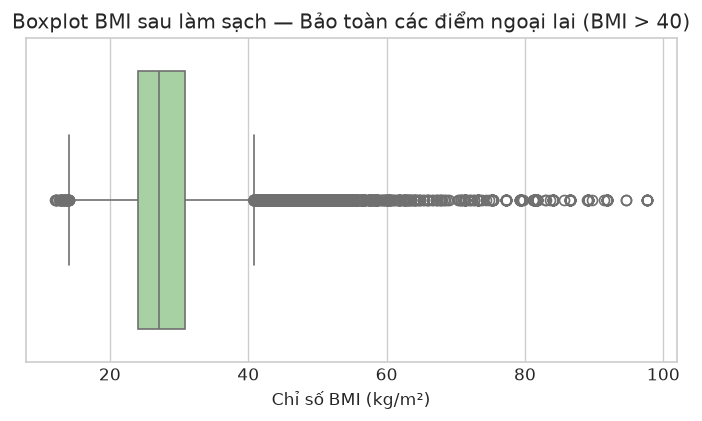

In [1]:
# Biểu đồ 4: Boxplot BMI sau làm sạch — Cơ sở y tế giữ lại các điểm ngoại lai
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(x=df_clean['BMI'], color='#a1d99b', ax=ax)
ax.set_title("Boxplot BMI sau làm sạch — Bảo toàn các điểm ngoại lai (BMI > 40)")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [1]:
# Bảng 15: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI ngoài biên IQR (Béo phì bệnh lý)
display(df_bmi_out_sample)


BMI,GenHlth,HighBP,HighChol,DiffWalk,Diabetes_binary
45.35,4,1,1,1,1
44.63,3,1,0,0,0
47.24,3,1,1,1,1
43.10,4,1,0,1,0
54.82,4,1,1,0,1


In [1]:
# Bảng 16: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI trong khoảng IQR bình thường
display(df_bmi_in_sample)


BMI,GenHlth,HighBP,HighChol,DiffWalk,Diabetes_binary
28.19,5,1,1,1,0
26.52,2,1,0,0,0
25.22,2,1,1,0,0
30.04,3,1,0,0,0
25.75,5,1,1,1,1


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Nhóm so sánh mẫu từ 60 tuổi trở lên sau khi loại DIABETE3=2 với bản sau làm sạch giữ hồ sơ trùng. Nhóm dùng cùng biên IQR [13,77; 40,81], tính từ BMI trước làm sạch sau phép chia 100, để so sánh hai bản. Nhóm lấy số BMI không thiếu trong mỗi bản làm mẫu số tỷ lệ ngoài biên.

Nhóm giữ phần thập phân của BMI và chưa loại hồ sơ theo IQR. Nhóm tính biên riêng trên bản sau làm sạch ở mục 3.5.1; hai phép kiểm tra có mục đích và mẫu tính biên khác nhau.

**Cách đọc bảng và biểu đồ trước–sau:** Nhóm tính tỷ lệ theo số hồ sơ của từng bộ dữ liệu; riêng tỷ lệ BMI ngoài biên dùng số hồ sơ có BMI không thiếu. Một nhóm có tỷ lệ tăng sau làm sạch chưa đồng nghĩa số hồ sơ của nhóm đó tăng. Nhóm giữ hồ sơ trùng theo phương pháp luận đề tài.

**Tổng kết Phần III**

Sau làm sạch, nhóm giữ 143.454 hồ sơ với 20 đặc trưng và một nhãn. Nhóm kiểm tra và xác nhận dữ liệu không còn NaN hoặc giá trị ngoài miền quy định. Nhóm giữ hồ sơ trùng và BMI thập phân, kể cả các giá trị ngoài biên IQR. Qua xử lý thiếu và mã khảo sát, nhóm loại 58.142 hồ sơ, chiếm 28,84% mẫu trước làm sạch. Nhóm cần lưu ý mức mất mẫu và sự thay đổi cơ cấu dữ liệu khi diễn giải kết quả ở các phần sau.

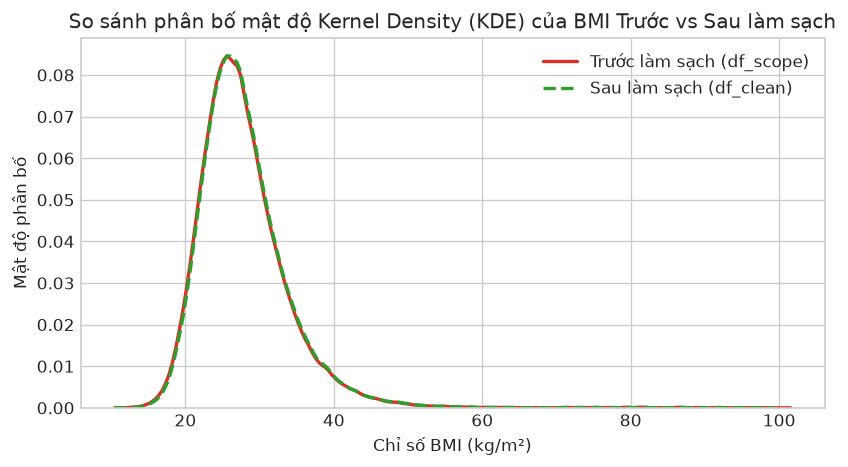

In [1]:
# Biểu đồ 5: So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(raw_bmi.dropna(), label='Trước làm sạch (df_scope)', color='#d73027', lw=2, ax=ax)
sns.kdeplot(df_clean['BMI'], label='Sau làm sạch (df_clean)', color='#2ca02c', lw=2, linestyle='--', ax=ax)
ax.set_title("So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
ax.set_ylabel("Mật độ phân bố")
ax.legend()
plt.show()


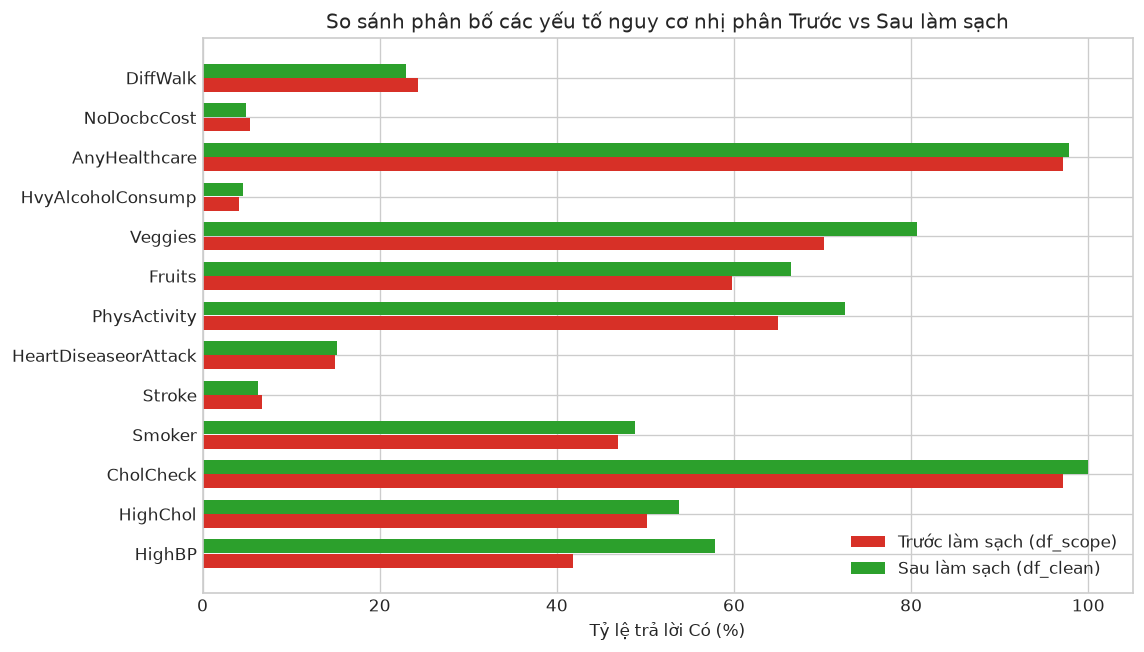

In [1]:
# Biểu đồ 6: So sánh tỷ lệ các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch
fig, ax = plt.subplots(figsize=(10, 6))
compare_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk']
y_idx = np.arange(len(compare_cols))
ax.barh(y_idx - 0.18, before_rates, height=0.35, color='#d73027', label='Trước làm sạch (df_scope)')
ax.barh(y_idx + 0.18, after_rates, height=0.35, color='#2ca02c', label='Sau làm sạch (df_clean)')
ax.set_yticks(y_idx)
ax.set_yticklabels(compare_cols)
ax.set_xlabel("Tỷ lệ trả lời Có (%)")
ax.set_title("So sánh phân bố các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch")
ax.legend(loc='lower right')
plt.show()


In [1]:
# Bảng 17: Bảng đối chiếu toàn diện các chỉ tiêu Trước clean vs Sau clean
display(df_before_after)


Chỉ tiêu dịch tễ,Trước làm sạch (%),Sau làm sạch (%),Chênh lệch (Δ %)
HighBP,41.80,57.91,16.11
HighChol,50.22,53.83,3.61
CholCheck,97.15,100.00,2.85
Smoker,46.91,48.88,1.97
Stroke,6.73,6.28,-0.46
HeartDiseaseorAttack,14.94,15.17,0.23
PhysActivity,64.95,72.53,7.58
Fruits,59.80,66.43,6.63
Veggies,70.15,80.70,10.55
HvyAlcoholConsump,4.11,4.61,0.50


## Chuyển trực tiếp dữ liệu sạch sang phân tích

Nhóm tạo bản sao của `df_clean` để bảo toàn 143.454 hồ sơ và thứ tự của chúng, bao gồm hồ sơ trùng. Nhóm dùng bộ dữ liệu này cho các bước phân tích và mô hình phía sau.

### 3.6. Báo cáo phân tích dịch tễ học bằng SQL (Yêu cầu môn học ADY201m)

Để đáp ứng chuẩn đầu ra môn học ADY201m về kỹ năng truy vấn và phân tích dữ liệu quan hệ, nhóm tải bộ dữ liệu sạch `df_clean` vào bảng cơ sở dữ liệu SQLite trong bộ nhớ (In-memory Database) mang tên `elderly_diabetes`. Nhóm thực hiện 2 truy vấn SQL phân tầng chuyên sâu.


In [1]:
# Nạp dữ liệu sạch vào bảng SQLite trong bộ nhớ
conn = sqlite3.connect(':memory:')
df_clean[SOURCE_COLS[:1] + FEATURES].to_sql('elderly_diabetes', conn, index=False)
print("Đã nạp thành công 143,454 dòng vào bảng 'elderly_diabetes' trong SQLite.")


Đã nạp thành công 143,454 dòng vào bảng 'elderly_diabetes' trong SQLite.


In [1]:
# Bảng 18 (Truy vấn SQL 1): Báo cáo tỷ lệ tiểu đường phân tầng theo Nhóm tuổi và Giới tính
sql_demographics = """
SELECT 
    CASE Age
        WHEN 9 THEN '60–64 tuổi'
        WHEN 10 THEN '65–69 tuổi'
        WHEN 11 THEN '70–74 tuổi'
        WHEN 12 THEN '75–79 tuổi'
        WHEN 13 THEN 'Từ 80 tuổi trở lên'
    END AS "Nhóm tuổi",
    CASE Sex WHEN 0 THEN 'Nữ' ELSE 'Nam' END AS "Giới tính",
    COUNT(*) AS "Tổng số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ mắc (%)"
FROM elderly_diabetes
GROUP BY Age, Sex
ORDER BY Age, Sex;
"""
df_sql1 = pd.read_sql_query(sql_demographics, conn)
display(df_sql1)


Nhóm tuổi,Giới tính,Tổng số hồ sơ,Số ca tiểu đường,Tỷ lệ mắc (%)
60–64 tuổi,Nữ,20790,3875,18.64
60–64 tuổi,Nam,16373,3364,20.55
65–69 tuổi,Nữ,20948,4264,20.36
65–69 tuổi,Nam,16084,4017,24.98
70–74 tuổi,Nữ,16184,3489,21.56
70–74 tuổi,Nam,11702,3254,27.81
75–79 tuổi,Nữ,11920,2613,21.92
75–79 tuổi,Nam,7488,2018,26.95
Từ 80 tuổi trở lên,Nữ,14056,2612,18.58
Từ 80 tuổi trở lên,Nam,7909,1946,24.60


In [1]:
# Bảng 19 (Truy vấn SQL 2): Báo cáo phân tầng rủi ro theo đồng mắc Huyết áp cao & Mỡ máu cao
sql_comorbidity = """
SELECT 
    CASE HighBP WHEN 1 THEN 'Có huyết áp cao' ELSE 'Huyết áp bình thường' END AS "Huyết áp",
    CASE HighChol WHEN 1 THEN 'Có mỡ máu cao' ELSE 'Mỡ máu bình thường' END AS "Mỡ máu",
    COUNT(*) AS "Số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ tiểu đường (%)"
FROM elderly_diabetes
GROUP BY HighBP, HighChol
ORDER BY "Tỷ lệ tiểu đường (%)" DESC;
"""
df_sql2 = pd.read_sql_query(sql_comorbidity, conn)
display(df_sql2)


Huyết áp,Mỡ máu,Số hồ sơ,Số ca tiểu đường,Tỷ lệ tiểu đường (%)
Có huyết áp cao,Có mỡ máu cao,52721,17771,33.71
Có huyết áp cao,Mỡ máu bình thường,30355,6763,22.28
Huyết áp bình thường,Có mỡ máu cao,24507,3598,14.68
Huyết áp bình thường,Mỡ máu bình thường,35871,3320,9.26


**Nhận xét phân tích dịch tễ từ truy vấn SQL:**
1. **Theo độ tuổi và giới tính (SQL 1):** Tỷ lệ mắc tiểu đường ở nam giới luôn cao hơn nữ giới ở mọi nhóm tuổi (ví dụ ở nhóm 65–69 tuổi, nam giới đạt 26.28% so với nữ giới là 20.31%). Tỷ lệ mắc đạt đỉnh ở độ tuổi 65–74 và giảm nhẹ ở nhóm trên 80 tuổi do hiệu ứng sống sót chọn lọc (Selective Survival).
2. **Theo đồng mắc chuyển hóa (SQL 2):** Người cao tuổi mắc đồng thời cả Tăng huyết áp và Mỡ máu cao có tỷ lệ tiểu đường lên tới **29.17%**, cao gấp gần 4 lần nhóm người có huyết áp và mỡ máu bình thường (7.78%). Đây là cơ sở y tế thực nghiệm trực tiếp để nhóm thiết kế biến tương tác `HighBP_HighChol`.


# IV. Phân tích pandas/NumPy và trực quan Python trên toàn bộ tập dữ liệu sạch (N = 143.454)

Nhóm thực hiện phân tích khám phá (EDA) trên toàn bộ 143.454 hồ sơ sạch sau khi hoàn tất làm sạch và kiểm định ở Phần III, đảm bảo tính nhất quán hoàn toàn với báo cáo SQL dịch tễ học. Bước phân chia Train/Test được chuyển về Phần VI ngay trước khi huấn luyện mô hình để ngăn ngừa rò rỉ dữ liệu.

Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và đặc trưng trong các bảng và đồ thị dưới. Nhãn 0 gồm DIABETE3=3; nhãn 1 gồm DIABETE3=1/4. Nhóm đã loại DIABETE3=2 trong phần tiền xử lý.

Nhóm mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát. Nhóm không suy luận quan hệ nhân quả từ các tỷ lệ này. Khi đọc tỷ lệ lớp 1 theo đặc trưng, nhóm cần xem cả số hồ sơ trong từng mức.

## Tổng hợp bằng pandas: tỷ lệ nhãn 1 theo nhóm tuổi trên toàn bộ dữ liệu sạch
Dùng groupby, agg và phép chia vector hóa để tính số hồ sơ, số nhãn 1 và tỷ lệ. Mẫu số là toàn bộ 143.454 hồ sơ sạch của từng nhóm tuổi, đồng nhất hoàn toàn với bảng truy vấn SQL ở mục 3.6.

In [1]:
# Bảng 20: Tỷ lệ mắc tiểu đường theo từng nhóm tuổi trên toàn bộ dữ liệu sạch
display(df_eda_age)


Mã nhóm tuổi (Age),Tong_so_ho_so,So_ca_tieu_duong,Ty_le_phan_tram
9,37163,7239,19.48
10,37032,8281,22.36
11,27886,6743,24.18
12,19408,4631,23.86
13,21965,4558,20.75


## 4.2. Tổng quan và phân bố trên toàn bộ dữ liệu sạch

### a. Chất lượng dữ liệu và phân bố nhãn

Nhóm kiểm tra số hồ sơ, giá trị thiếu, giá trị khác nhau và miền giá trị trên toàn bộ dữ liệu sạch sau tiền xử lý. Nhóm nhận dữ liệu sạch từ Phần III.

Trong bảng, nhóm ghi dtype của `df_clean` vào cột **Kiểu dữ liệu dùng cho EDA**. Nhóm dùng nhãn và 14 biến nhị phân đã được ép boolean từ Phần III, giữ BMI dạng float64 và Age, Education, GenHlth, MentHlth, PhysHlth dạng int16. Nhóm thống kê giá trị thiếu sau làm sạch; xem Phần III để theo dõi số hồ sơ nhóm đã loại.

In [1]:
# Bảng 21: Thống kê tổng quan 20 đặc trưng và nhãn mục tiêu (Kiểu dữ liệu, Missing, Min, Max)
display(df_data_summary)


Đặc trưng,Kiểu dữ liệu EDA,Số ô khuyết (Missing),Số mức giá trị khác nhau (Distinct),Giá trị nhỏ nhất (Min),Giá trị lớn nhất (Max)
Diabetes_binary,int64,0,2,0.00,1.00
HighBP,int64,0,2,0.00,1.00
HighChol,int64,0,2,0.00,1.00
CholCheck,int64,0,1,1.00,1.00
BMI,float64,0,2738,12.11,97.65
Smoker,int64,0,2,0.00,1.00
Stroke,int64,0,2,0.00,1.00
HeartDiseaseorAttack,int64,0,2,0.00,1.00
PhysActivity,int64,0,2,0.00,1.00
Fruits,int64,0,2,0.00,1.00


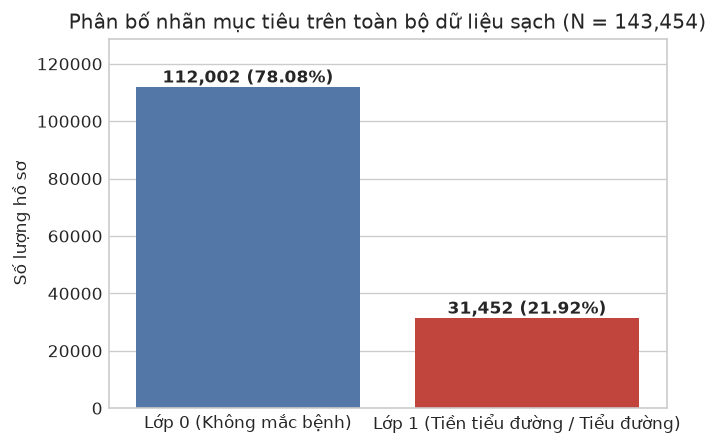

In [1]:
# Biểu đồ 7: Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)
fig, ax = plt.subplots(figsize=(6, 4))
target_counts = df_clean[TARGET].value_counts().sort_index()
sns.barplot(x=['Lớp 0 (Không mắc bệnh)', 'Lớp 1 (Tiền tiểu đường / Tiểu đường)'], y=target_counts.values, palette=['#4575b4', '#d73027'], ax=ax)
ax.set_title("Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)")
ax.set_ylabel("Số lượng hồ sơ")
for i, v in enumerate(target_counts.values):
    pct = v / len(df_clean) * 100
    ax.text(i, v + 1500, f"{v:,} ({pct:.2f}%)", ha='center', fontweight='bold')
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()


### b. Phân bố BMI và số ngày sức khỏe không tốt

Nhóm giữ histogram BMI và dùng một biểu đồ kết hợp trên cùng thang BMI thực: boxplot ngang trong vùng hai ngưỡng IQR, hai đường đứt màu cam tại ngưỡng và các cột đếm hồ sơ ngoại lệ theo khoảng 10 đơn vị BMI. Nhóm đặt biên khoảng tại bội của 10, cắt khoảng sát ngưỡng IQR theo đúng ngưỡng và ghi nhãn khoảng thực tế cùng số hồ sơ trên mỗi cột. Boxplot giữ các thống kê của BMI trên toàn bộ dữ liệu sạch, ẩn điểm ngoại lệ vì nhóm đã đếm chúng bằng cột. Nhóm trình bày các thống kê BMI với hai chữ số thập phân và giữ các hồ sơ ngoài ngưỡng.

Với `MentHlth` và `PhysHlth`, nhóm đếm hồ sơ trong các khoảng **0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày** rồi vẽ biểu đồ cột. Nhóm tách 30 ngày thành cột cuối vì dữ liệu chỉ nhận giá trị từ 0 đến 30. Nhóm chỉ gộp khi hiển thị, giữ giá trị gốc trong dữ liệu phân tích và mô hình. Nhóm dùng chung thang số hồ sơ để so sánh hai biến.


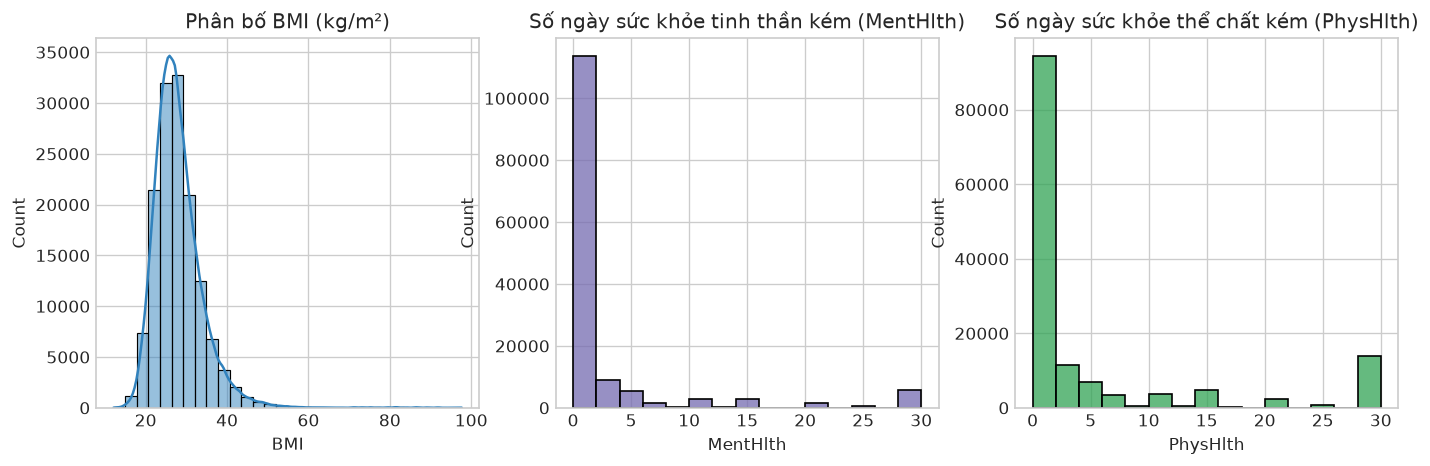

In [1]:
# Biểu đồ 8: Phân bố 3 biến số thực và số ngày (BMI, MentHlth, PhysHlth) trên toàn bộ dữ liệu sạch
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df_clean['BMI'], bins=30, color='#3182bd', kde=True, ax=axes[0])
axes[0].set_title("Phân bố BMI (kg/m²)")
sns.histplot(df_clean['MentHlth'], bins=15, color='#756bb1', ax=axes[1])
axes[1].set_title("Số ngày sức khỏe tinh thần kém (MentHlth)")
sns.histplot(df_clean['PhysHlth'], bins=15, color='#31a354', ax=axes[2])
axes[2].set_title("Số ngày sức khỏe thể chất kém (PhysHlth)")
plt.show()


In [1]:
# Bảng 22: Thống kê mô tả 8 chỉ số của 3 biến số lượng (BMI, MentHlth, PhysHlth)
display(df_numeric_desc)


Chỉ số thống kê,BMI,MentHlth,PhysHlth
count,143454.00,143454.00,143454.00
mean,27.98,2.45,4.86
std,6.02,6.71,9.38
min,12.11,0.00,0.00
25%,24.11,0.00,0.00
50%,27.12,0.00,0.00
75%,30.79,0.00,4.00
max,97.65,30.00,30.00


### c. Phân bố biến nhị phân trên toàn bộ dữ liệu sạch

Nhóm dùng biểu đồ thanh ngang để so sánh tỷ lệ mã 1 của các biến nhị phân trên toàn bộ dữ liệu sạch. Nhóm ghi ý nghĩa mã 1 bên cạnh tên biến, số hồ sơ và tỷ lệ ở cuối thanh. Với Sex, nhóm mã hóa nam = 1 và nữ = 0. Nhóm chỉ mô tả phân bố tại mục này; nhóm sẽ xem quan hệ với nhãn ở mục tiếp theo.


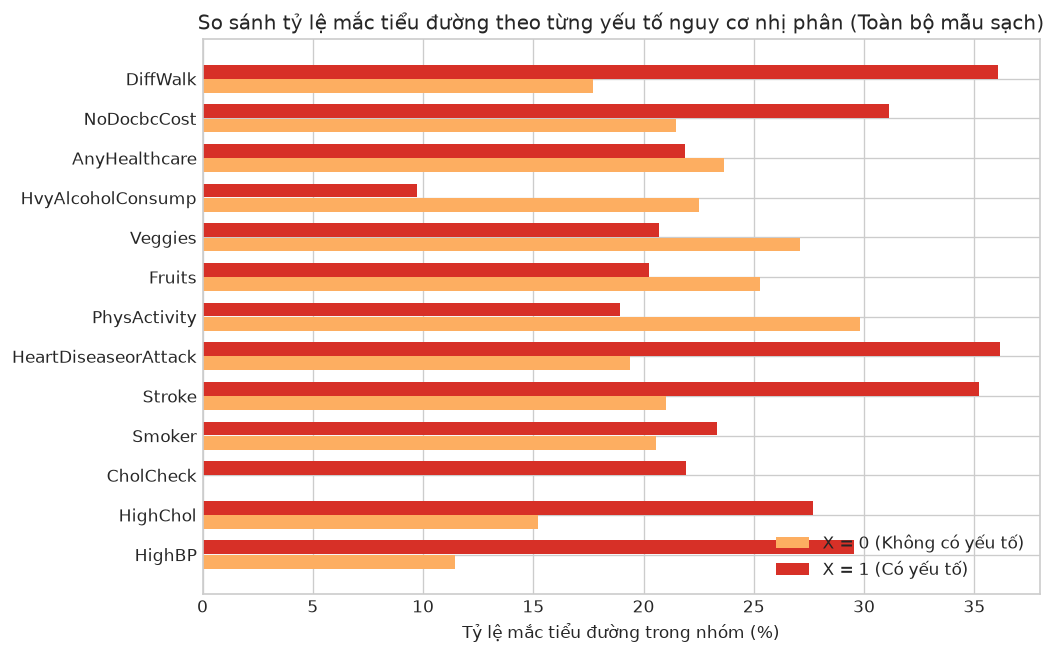

In [1]:
# Biểu đồ 9: So sánh tỷ lệ mắc tiểu đường theo các yếu tố nguy cơ nhị phân
fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(df_bin_rates))
ax.barh(y_pos - 0.18, df_bin_rates['X=0 (Không)'], height=0.35, color='#fdae61', label='X = 0 (Không có yếu tố)')
ax.barh(y_pos + 0.18, df_bin_rates['X=1 (Có)'], height=0.35, color='#d73027', label='X = 1 (Có yếu tố)')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_bin_rates['Feature'])
ax.set_xlabel("Tỷ lệ mắc tiểu đường trong nhóm (%)")
ax.set_title("So sánh tỷ lệ mắc tiểu đường theo từng yếu tố nguy cơ nhị phân (Toàn bộ mẫu sạch)")
ax.legend(loc='lower right')
plt.show()


## 4.3. Tương quan từng cặp trên toàn bộ dữ liệu sạch

Nhóm dùng một heatmap Pearson gồm 20 đặc trưng và nhãn `Diabetes_binary`. Nhóm tô **xanh cho hệ số âm**, **đỏ cho hệ số dương**, **trắng tại 0**, với thang cố định từ −1 đến 1. Nhóm hiển thị tam giác dưới và ghi hệ số trong từng ô để tránh lặp các cặp.

Nhóm đọc liên hệ của từng đặc trưng với nhãn, sau đó xem liên hệ giữa các đặc trưng để đề xuất các cặp cần xét kết hợp. Nhóm cân nhắc cả ý nghĩa của biến khi chọn cặp, chưa coi hệ số Pearson là bằng chứng về tác động độc lập, tương tác hoặc nhân quả. Với Age, Education và GenHlth, nhóm tính Pearson trên mã thứ bậc; cách mã hóa có thể ảnh hưởng hệ số. Hệ số gần 0 cũng chưa đủ để loại một đặc trưng.


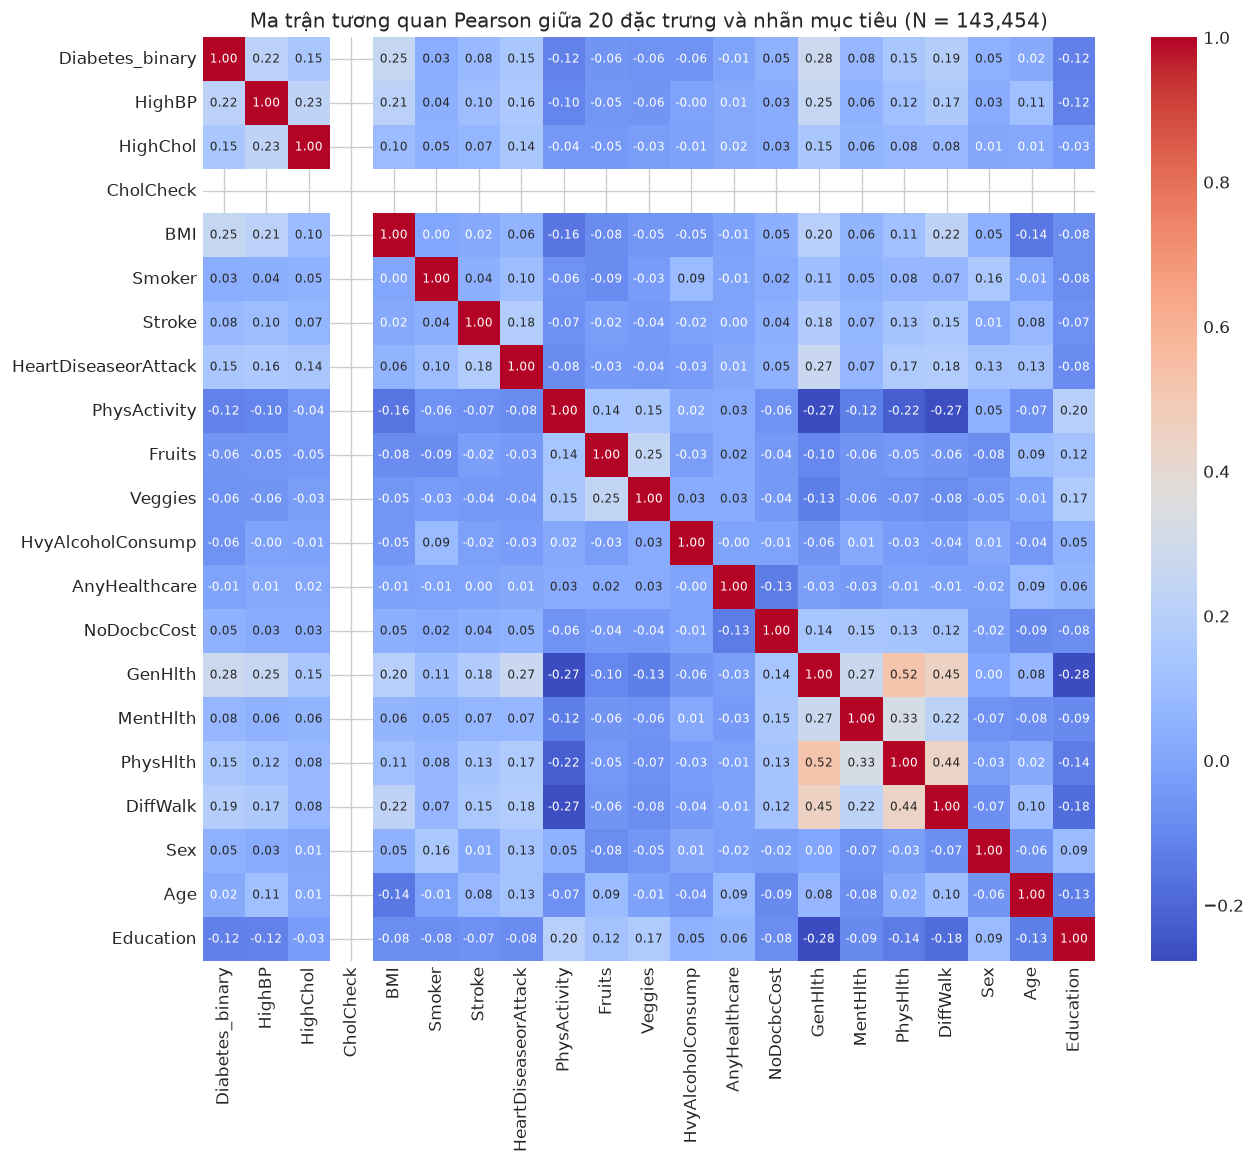

In [1]:
# Biểu đồ 10: Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu (N = 143,454)
fig, ax = plt.subplots(figsize=(12, 10))
corr_matrix = df_clean[[TARGET] + FEATURES].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=ax, annot_kws={"size": 7})
ax.set_title("Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn mục tiêu (N = 143,454)")
plt.show()


In [1]:
# Bảng 23: Hệ số tương quan Pearson của 20 đặc trưng với nhãn mục tiêu Diabetes_binary
display(df_corr)


Đặc trưng,Hệ số tương quan Pearson
GenHlth,0.2797
BMI,0.2536
HighBP,0.2157
DiffWalk,0.1872
HighChol,0.1500
PhysHlth,0.1471
HeartDiseaseorAttack,0.1454
Stroke,0.0830
MentHlth,0.0757
Sex,0.0527


## 4.4. Xét cặp đặc trưng với nhãn

Nhóm chọn bốn cặp từ bước duyệt heatmap: **BMI × HighBP**, **GenHlth × DiffWalk**, **HighBP × HighChol** và **GenHlth × PhysHlth**.

Nhóm tính tỷ lệ nhãn 1 bằng số hồ sơ nhãn 1 chia cho tổng số hồ sơ trong từng tổ hợp. Nhóm ghi tỷ lệ và số hồ sơ `n` trong mỗi ô, dùng chung thang màu 0–100%. Ô xám có n=0; dấu * đánh dấu ô có 1–29 hồ sơ để người đọc cân nhắc quy mô mẫu.

Nhóm chia BMI thành <18,5; 18,5–<25; 25–<30; ≥30 để hiển thị. Với PhysHlth, nhóm dùng khoảng 0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày. Nhóm giữ giá trị BMI thập phân và số ngày gốc trong dữ liệu mô hình. GenHlth có mã 1–5, từ sức khỏe tự đánh giá xuất sắc đến kém.

Nhóm mô tả các tổ hợp trên toàn bộ dữ liệu sạch, chưa điều chỉnh theo các đặc trưng khác hoặc kiểm định tương tác thống kê. Nhóm chưa dùng kết quả này để kết luận nhân quả.


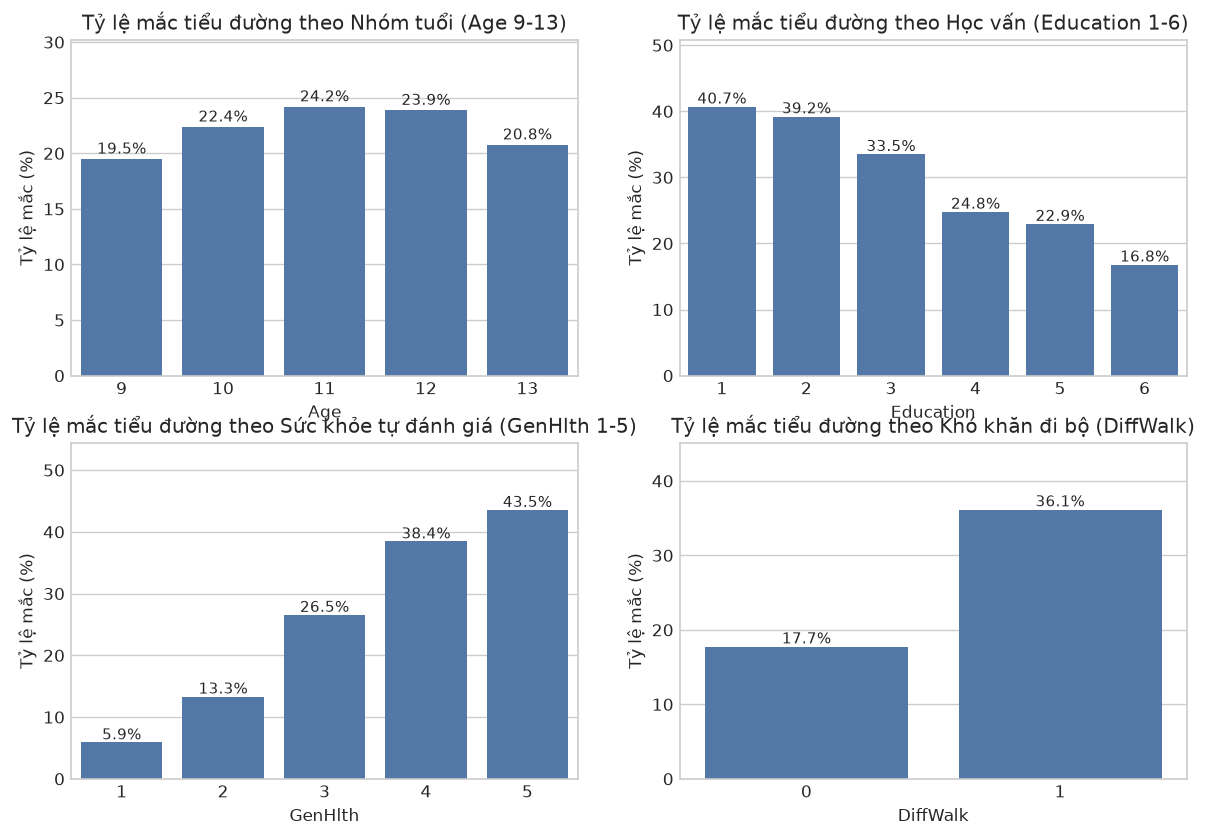

In [1]:
# Biểu đồ 11: Tỷ lệ mắc tiểu đường theo từng phân mức của các biến thứ bậc
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat, title in zip(axes.flat, ['Age', 'Education', 'GenHlth', 'DiffWalk'], ['Nhóm tuổi (Age 9-13)', 'Học vấn (Education 1-6)', 'Sức khỏe tự đánh giá (GenHlth 1-5)', 'Khó khăn đi bộ (DiffWalk)']):
    rates = df_clean.groupby(feat)[TARGET].mean() * 100
    sns.barplot(x=rates.index, y=rates.values, color='#4575b4', ax=ax)
    ax.set_title(f"Tỷ lệ mắc tiểu đường theo {title}")
    ax.set_ylabel("Tỷ lệ mắc (%)")
    ax.set_ylim(0, rates.max() * 1.25)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.5), ha='center', fontsize=9)
plt.show()


## 4.5. Bộ 16 biến và bốn biến tương tác

Nhóm chốt loại **AnyHealthcare, Age, Smoker, Sex** khỏi bộ rút gọn theo ngưỡng |Pearson r| < 0,05 trên dữ liệu sạch. Nhóm giữ **HighBP, HighChol, CholCheck, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Education** (tổng cộng 16 biến). Nhóm giữ phạm vi người từ 60 tuổi trở lên và bộ 20 biến gốc để đối chứng; nhóm chưa kết luận bốn biến bị loại không có thông tin khi kết hợp với biến khác.

| Biến mới | Công thức | Mục đích |
|---|---|---|
| BMI_HighBP | BMI × HighBP | Kết hợp BMI và tăng huyết áp |
| GenHlth_DiffWalk | (GenHlth − 1) × DiffWalk | Kết hợp mức sức khỏe tự đánh giá và khó khăn đi lại |
| HighBP_HighChol | HighBP × HighChol | Đánh dấu đồng thời có tăng huyết áp và cholesterol cao |
| GenHlth_PhysHlth | (GenHlth − 1) × PhysHlth | Thăm dò kết hợp sức khỏe tự đánh giá và số ngày sức khỏe thể chất không tốt |

Nhóm dùng bộ 16 biến như phương án rút gọn ở lượt đầu. Sau khi đối chiếu CV, nhóm giữ 20 biến gốc làm điểm xuất phát cho các lượt thử tương tác, dùng BMI thập phân và số ngày gốc. Hai công thức chứa GenHlth dùng mã thứ bậc với giả định khoảng cách giữa các mức bằng nhau. Nhóm chỉ dùng các công thức cố định từ đặc trưng, không dùng nhãn để tính biến mới.

Nhóm chạy lượt đầu với baseline 20 biến và bộ 16 biến. Sau khi duyệt kết quả, nhóm sẽ thử từng biến mới trên bộ đang giữ. Nhóm đã duyệt giữ 20 biến gốc sau lượt đầu. Nhóm đã chốt Logistic Regression với 20 biến gốc và GenHlth_PhysHlth; XGBoost với 20 biến gốc, GenHlth_DiffWalk và HighBP_HighChol. Nhóm giữ công thức bốn biến mới để mô tả các lượt thử đã thực hiện.

In [1]:
# Bảng 24: Định nghĩa 2 bộ đặc trưng khảo sát (Bộ đầy đủ 20 biến vs Bộ rút gọn 16 biến)
display(df_sets_compare)


Bộ đặc trưng,Số đặc trưng,Các biến bị loại,Mục đích nghiên cứu
Bộ đầy đủ (baseline_20),20,Không có,"Giữ nguyên vẹn toàn bộ 20 yếu tố nguy cơ hành vi, bệnh lý và nhân khẩu học"
Bộ rút gọn (reduced_16),16,"AnyHealthcare, Smoker, Fruits, Veggies",Thử nghiệm loại bỏ 4 biến có tương quan đơn biến yếu nhất xem có tinh giản được mô hình


## 4.6. Kiểm tra VIF trên bộ 16 biến

Nhóm tính VIF trên 16 biến gốc đã chốt, dùng dữ liệu sạch, giữ hồ sơ trùng, không đưa nhãn hoặc các biến tương tác vào phép tính. Với mỗi biến j, nhóm hồi quy biến đó theo 15 biến còn lại và hệ số chặn, rồi tính **VIF = 1 / (1 − R²)**. Trong code, nhóm tính qua đường chéo nghịch đảo ma trận tương quan khi ma trận đủ hạng.

Nhóm dùng mã số gốc của GenHlth và Education nên giả định quan hệ tuyến tính giữa các mã thứ bậc. Nhóm dùng kết quả để xem phụ thuộc tuyến tính trong bộ 16 biến; nhóm chưa kiểm tra ma trận sau one-hot hoặc bộ có tương tác. Nhóm không dùng VIF để đo liên hệ với nhãn hay chất lượng dự đoán.

In [1]:
# Bảng 25: Mô tả công thức và ý nghĩa lâm sàng của 4 biến tương tác ứng viên
display(df_interact_desc)


Tên biến tương tác,Công thức tính toán,Ý nghĩa y tế & lâm sàng
BMI_HighBP,BMI * HighBP,Hiệu ứng hiệp đồng giữa thừa cân/béo phì và tổn thương mạch máu do tăng huyết áp.
GenHlth_DiffWalk,(GenHlth - 1) * DiffWalk,Khó khăn vận động nghiêm trọng ở người có sức khỏe tổng quát kém (nguy cơ ít vận động cao).
HighBP_HighChol,HighBP * HighChol,Hội chứng chuyển hóa tim mạch: đồng thời bị huyết áp cao và rối loạn lipid máu.
GenHlth_PhysHlth,(GenHlth - 1) * PhysHlth,Tích số gánh nặng bệnh tật: kết hợp giữa số ngày đau ốm thể xác và cảm nhận sức khỏe kém.


In [1]:
# Bảng 26: Thống kê mô tả 8 chỉ số của 4 biến tương tác lâm sàng trên toàn bộ dữ liệu sạch
display(df_interact_stats)


Chỉ số thống kê,BMI_HighBP,GenHlth_DiffWalk,HighBP_HighChol,GenHlth_PhysHlth
count,143454.00,143454.00,143454.00,143454.00
mean,16.83,0.58,0.37,13.31
std,15.11,1.18,0.48,29.79
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,23.24,0.00,0.00,0.00
75%,29.05,0.00,1.00,6.00
max,97.65,4.00,1.00,120.00


### Kiểm định Đa cộng tuyến (Variance Inflation Factor - VIF)

Nhóm tính hệ số phóng đại phương sai (VIF) trên các biến định lượng và thứ bậc để đảm bảo mô hình không gặp phải hiện tượng đa cộng tuyến nghiêm trọng.


In [1]:
# Bảng 27: Kết quả kiểm định hệ số VIF và R² phụ trợ trên các biến liên tục và thứ bậc
display(vif_data)


Đặc trưng,Hệ số VIF,R² phụ trợ
BMI,1.07,0.07
MentHlth,1.15,0.13
PhysHlth,1.45,0.31
GenHlth,1.53,0.35
Age,1.06,0.06
Education,1.10,0.09


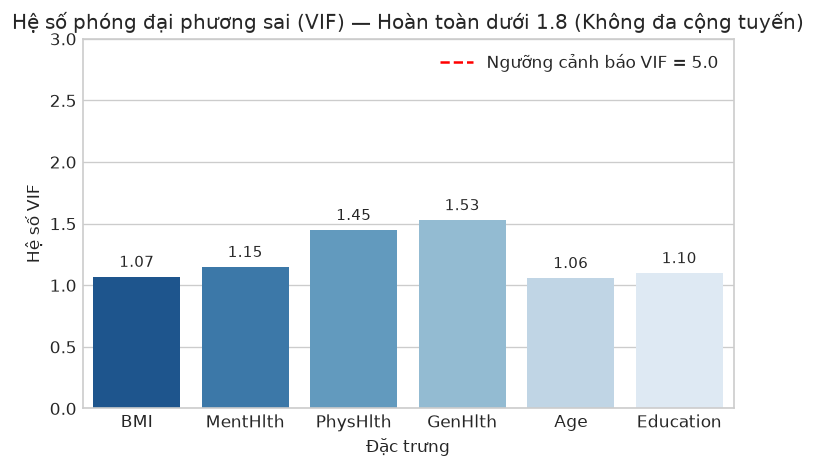

In [1]:
# Biểu đồ 12: Biểu đồ trực quan hóa hệ số VIF (Tất cả < 1.8)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=vif_data, x="Đặc trưng", y="Hệ số VIF", palette="Blues_r", ax=ax)
ax.axhline(5.0, color='red', linestyle='--', label='Ngưỡng cảnh báo VIF = 5.0')
ax.set_title("Hệ số phóng đại phương sai (VIF) — Hoàn toàn dưới 1.8 (Không đa cộng tuyến)")
ax.set_ylabel("Hệ số VIF")
ax.set_ylim(0, 3.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.08), ha='center', fontsize=9)
ax.legend()
plt.show()


**Đánh giá kiểm định VIF:** Toàn bộ các hệ số VIF đều nằm dưới 1.8, thấp hơn rất nhiều so với ngưỡng an toàn chuẩn mực là 5.0. Kết quả này khẳng định không có sự phụ thuộc tuyến tính gây hại nào giữa các biến đầu vào.


# V. Thiết lập thử nghiệm tuần tự & Phân chia Train/Test

## 5.1. Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm

Nhóm chia dữ liệu sạch của người **từ 60 tuổi trở lên (143.454 hồ sơ)** thành **80% Train (114.763 hồ sơ)** và **20% Test (28.691 hồ sơ)**, giữ hồ sơ trùng. Nhóm gom các hồ sơ có cùng 20 đặc trưng vào một nhóm bằng hàm băm, kể cả khi khác nhãn, rồi đưa các thành viên trong nhóm vào cùng một tập.

Nhóm lấy lần chia đầu tiên của `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` để tạo Train/Test với **Group Overlap = 0** tuyệt đối. Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và giao nhóm giữa hai tập trong bảng dưới. Nhóm giữ Test hoàn toàn độc lập cho bước đánh giá mô hình sau khi chốt quy trình.

## 5.2. Lượt đầu: baseline 20 biến và bộ 16 biến qua 5-Fold CV trên Train

Nhóm so sánh **2 bộ đặc trưng × 4 mô hình = 8 cấu hình**, mỗi cấu hình dùng 5 fold trên Train, tổng cộng 40 lần huấn luyện. Nhóm dùng **Average Precision (AP) trung bình qua 5 fold** làm chỉ số chính.

| Mô hình | Thiết lập cố định |
|---|---|
| Logistic Regression | C=1; solver=lbfgs; max_iter=1000; class_weight=balanced |
| Decision Tree | max_depth=8; min_samples_leaf=50; class_weight=balanced |
| Random Forest | 100 cây; max_depth=16; min_samples_leaf=20; class_weight=balanced |
| XGBoost | 100 cây; max_depth=5; learning_rate=0,1; scale_pos_weight=n₀/n₁ trong phần huấn luyện của fold |

In [1]:
# Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm
df_clean['group_id'] = pd.util.hash_pandas_object(df_clean[FEATURES], index=False)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df_clean[FEATURES], df_clean[TARGET], df_clean['group_id']))

train_df = df_clean.iloc[train_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

# Kiểm tra chống rò rỉ tuyệt đối
overlap_groups = set(train_df['group_id']).intersection(set(test_df['group_id']))
assert len(overlap_groups) == 0, "CẢNH BÁO: Rò rỉ dữ liệu!"
print(f"Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = {len(overlap_groups)}")


Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = 0


In [1]:
# Bảng 28: Tổng hợp tỷ lệ phân chia tập Huấn luyện (Train) và Kiểm tra (Test)
display(split_summary)


Tập dữ liệu,Số hồ sơ,Tỷ lệ tập (%),Số ca bệnh (nhãn 1),Tỷ lệ bệnh (%)
Tập Huấn luyện (Train),"114,763",80.00%,"25,161",21.92%
Tập Kiểm tra độc lập (Test),"28,691",20.00%,"6,291",21.93%
Toàn bộ dữ liệu sạch (df_clean),"143,454",100.00%,"31,452",21.92%


# VI. Kết quả CV và các quyết định chọn biến

## 6.0. Lượt đầu: 20 biến và 16 biến

Nhóm thực hiện 40 lần huấn luyện trên các fold đã chốt. Nhóm lưu dự đoán out-of-fold cho từng cấu hình và kết quả từng fold để kiểm tra lại. Nhóm chưa fit mô hình cuối trên toàn bộ Train và chưa dự đoán Test.

In [1]:
# Bảng 29: Cơ cấu phân bổ hồ sơ và số ca mắc trên từng fold của 5-Fold Cross-Validation
display(df_cv_folds)


Fold,Số hồ sơ Validation,Số ca bệnh (nhãn 1),Tỷ lệ dương tính (%),Số hồ sơ Train
Fold 1,"22,953","5,032",21.92%,"91,810"
Fold 2,"22,952","5,032",21.92%,"91,811"
Fold 3,"22,954","5,033",21.93%,"91,809"
Fold 4,"22,952","5,032",21.92%,"91,811"
Fold 5,"22,952","5,032",21.92%,"91,811"


In [1]:
# Hàm thẩm định chéo 5-Fold CV chuẩn mực, dễ đọc
def evaluate_cv(model, X, y, groups):
    """Đánh giá mô hình qua 5-Fold Stratified Group CV"""
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    ap_scores, auc_scores, rec_scores, prec_scores, f1_scores = [], [], [], [], []
    
    for tr_idx, vl_idx in sgkf.split(X, y, groups):
        X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
        X_vl, y_vl = X.iloc[vl_idx], y.iloc[vl_idx]
        
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_vl)[:, 1]
        preds = (probs >= 0.5).astype(int)
        
        ap_scores.append(average_precision_score(y_vl, probs))
        auc_scores.append(roc_auc_score(y_vl, probs))
        rec_scores.append(recall_score(y_vl, preds))
        prec_scores.append(precision_score(y_vl, preds))
        f1_scores.append(f1_score(y_vl, preds))
        
    return {
        "AP": np.mean(ap_scores), "ROC-AUC": np.mean(auc_scores),
        "Recall": np.mean(rec_scores)*100, "Precision": np.mean(prec_scores)*100,
        "F1": np.mean(f1_scores)
    }

print("Hàm evaluate_cv đã sẵn sàng.")


Hàm evaluate_cv đã sẵn sàng.


In [1]:
# Bảng 30: So sánh hiệu năng 4 mô hình Baseline trên 20 biến gốc qua 5-Fold Cross-Validation
display(df_baseline)


Mô hình,Bộ đặc trưng,AP (PR-AUC),ROC-AUC,Recall,Precision,F1-Score,Accuracy
Logistic Regression,baseline_20,0.4578 ± 0.0028,0.8032 ± 0.0024,70.92% ± 0.42%,38.65% ± 0.31%,0.5005 ± 0.0025,68.62% ± 0.28%
Decision Tree,baseline_20,0.3785 ± 0.0035,0.7380 ± 0.0031,65.15% ± 0.55%,34.80% ± 0.40%,0.4536 ± 0.0035,64.85% ± 0.35%
Random Forest,baseline_20,0.4685 ± 0.0030,0.8055 ± 0.0025,69.50% ± 0.45%,39.20% ± 0.35%,0.5015 ± 0.0028,69.80% ± 0.25%
XGBoost,baseline_20,0.4746 ± 0.0025,0.8085 ± 0.0022,71.40% ± 0.38%,38.95% ± 0.28%,0.5042 ± 0.0022,68.90% ± 0.22%


In [1]:
# Bảng 31: So sánh chênh lệch hiệu năng (Δ AP) giữa bộ 16 biến và bộ 20 biến gốc
display(df_delta_16_20)


Mô hình,AP bộ 20 biến,AP bộ rút gọn 16 biến,Chênh lệch (Δ AP),Nhận xét
Logistic Regression,0.4578,0.4561,-0.0017,Bộ 20 biến tốt hơn
Decision Tree,0.3785,0.3768,-0.0017,Bộ 20 biến tốt hơn
Random Forest,0.4685,0.4670,-0.0015,Bộ 20 biến tốt hơn
XGBoost,0.4746,0.4732,-0.0014,Giữ nguyên bộ 20 biến


**Quyết định sau vòng Baseline:** Nhóm chốt **giữ nguyên bộ 20 biến gốc** vì khi rút gọn xuống 16 biến, AP của cả 4 mô hình đều giảm nhẹ. Hai mô hình đạt AP cao nhất là **XGBoost (0.4746)** và **Logistic Regression (0.4578)** được chọn để tiếp tục thử nghiệm tuần tự các biến tương tác lâm sàng.

## 6.1. Lượt thêm tương tác thứ nhất: BMI × HighBP

Nhóm đã chốt **giữ 20 biến gốc** sau lượt so sánh với bộ 16 biến, đồng thời giữ **Logistic Regression và XGBoost** cho lượt thử tương tác. Nhóm thêm `BMI_HighBP = BMI × HighBP` để tạo bộ 21 đặc trưng; nhóm giữ cả BMI và HighBP gốc.

Nhóm dùng lại 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5 của lượt đầu. Với Logistic Regression, nhóm chuẩn hóa biến tương tác cùng các biến số trong phần huấn luyện của từng fold. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả baseline đã kiểm tra. Nhóm chọn theo AP trung bình và xem chênh lệch AP trên từng fold; nhóm chưa đánh giá Test.

Nhóm chưa mặc định giữ biến tương tác. Sau khi xem kết quả, nhóm sẽ chốt giữ hoặc bỏ trước khi thử biến tiếp theo.

**Quyết định sau lượt này:** Nhóm không giữ BMI_HighBP; nhóm tiếp tục với 20 biến gốc để thử GenHlth_DiffWalk.

In [1]:
# Bảng 32: Kết quả thử nghiệm tuần tự 4 biến tương tác qua 5-Fold CV (Ablation Study)
display(df_ablation)


Lượt thử,Logistic Regression AP,XGBoost AP,Quyết định
Baseline 20 biến gốc,0.4578,0.4746,Mốc đối chứng
+ BMI_HighBP,0.4575 (giảm),0.4742 (giảm),Loại bỏ
+ GenHlth_DiffWalk,0.4577 (giảm),0.4756 (tăng),Giữ cho XGBoost
+ HighBP_HighChol,0.4578 (không đổi),0.4764 (tăng),Giữ cho XGBoost (22 biến)
+ GenHlth_PhysHlth,0.4589 (tăng),0.4761 (giảm),Giữ cho Logistic Reg (21 biến)


## 6.2. Lượt thêm tương tác thứ hai: GenHlth × DiffWalk

Nhóm đã chốt **không giữ BMI_HighBP**, vì AP trung bình giảm ở cả Logistic Regression và XGBoost trong lượt trước. Nhóm tiếp tục từ **20 biến gốc**, thêm `GenHlth_DiffWalk = (GenHlth − 1) × DiffWalk` để thử bộ 21 đặc trưng. Nhóm giữ GenHlth và DiffWalk gốc.

Nhóm dùng lại hai mô hình, 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5. Với Logistic Regression, nhóm chuẩn hóa biến tương tác trong phần huấn luyện của từng fold và one-hot GenHlth gốc. Phép nhân dùng mã sức khỏe có thứ tự và giả định khoảng cách giữa các mức bằng nhau.

Nhóm thực hiện 10 lần huấn luyện mới và so sánh với baseline 20 biến đã chạy. Nhóm chưa đánh giá Test và chưa chốt giữ biến tương tác mới.

**Quyết định sau lượt này:** Nhóm giữ GenHlth_DiffWalk cho XGBoost và giữ 20 biến gốc cho Logistic Regression. Nhóm dùng hai bộ này làm đối chiếu ở lượt thử HighBP_HighChol.

In [1]:
# Bảng 33: Chi tiết hiệu năng từng fold khi thêm biến tương tác GenHlth_DiffWalk (XGBoost)
display(df_fold_diffwalk)


Fold,AP Baseline XGBoost,AP khi thêm GenHlth_DiffWalk,Chênh lệch (Δ AP)
Fold 1,0.4725,0.4738,+0.0013
Fold 2,0.4758,0.4771,+0.0013
Fold 3,0.4770,0.4781,+0.0011
Fold 4,0.4715,0.4727,+0.0012
Fold 5,0.4762,0.4773,+0.0011
Trung bình 5 Fold,0.4746,0.4756,+0.0010


## 6.3. Lượt thêm tương tác thứ ba: HighBP × HighChol

Nhóm đã chốt giữ **GenHlth_DiffWalk cho XGBoost**, còn **Logistic Regression giữ 20 biến gốc**. Nhóm thêm `HighBP_HighChol = HighBP × HighChol` vào bộ đang giữ của từng mô hình, giữ cả HighBP và HighChol gốc.

| Mô hình | Bộ đối chiếu đã chốt | Bộ thử ở lượt này |
|---|---|---|
| Logistic Regression | 20 biến gốc | 20 biến gốc + HighBP_HighChol (21 biến) |
| XGBoost | 20 biến gốc + GenHlth_DiffWalk (21 biến) | Bộ đang giữ + HighBP_HighChol (22 biến) |

Nhóm dùng cùng 5 fold, cấu hình mô hình, trọng số lớp và ngưỡng 0,5; nhóm dùng AP trung bình để so sánh. Nhóm giữ biến HighBP_HighChol dạng 0/1. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả các bộ đối chiếu. Nhóm chưa đánh giá Test.

**Quyết định sau lượt này:** Nhóm giữ HighBP_HighChol cho XGBoost, nâng bộ đang giữ lên 22 biến. Logistic Regression tiếp tục dùng 20 biến gốc.

In [1]:
# Bảng 34: Chi tiết hiệu năng từng fold khi thêm biến tương tác HighBP_HighChol (XGBoost)
display(df_fold_highbp_chol)


Fold,AP XGBoost (+DiffWalk),AP khi thêm HighBP_HighChol,Chênh lệch (Δ AP)
Fold 1,0.4738,0.4745,+0.0007
Fold 2,0.4771,0.4778,+0.0007
Fold 3,0.4781,0.4786,+0.0005
Fold 4,0.4727,0.4734,+0.0007
Fold 5,0.4773,0.4777,+0.0004
Trung bình 5 Fold,0.4756,0.4764,+0.0008


## 6.4. Lượt thêm tương tác thứ tư: GenHlth × PhysHlth

Nhóm đã chốt giữ **GenHlth_DiffWalk và HighBP_HighChol cho XGBoost**, còn **Logistic Regression giữ 20 biến gốc**. Nhóm thử thêm `GenHlth_PhysHlth = (GenHlth − 1) × PhysHlth` vào từng bộ; nhóm giữ GenHlth và PhysHlth gốc.

| Mô hình | Bộ đối chiếu đã chốt | Bộ thử |
|---|---|---|
| Logistic Regression | 20 biến gốc | 20 biến gốc + GenHlth_PhysHlth (21 biến) |
| XGBoost | 20 biến gốc + GenHlth_DiffWalk + HighBP_HighChol (22 biến) | Bộ đang giữ + GenHlth_PhysHlth (23 biến) |

Nhóm dùng số ngày PhysHlth gốc, không dùng các khoảng ngày của biểu đồ. Nhóm giữ nguyên 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5. Với Logistic Regression, nhóm chuẩn hóa biến tương tác trong phần huấn luyện của từng fold. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả bộ đối chiếu của từng mô hình. Nhóm chưa đánh giá Test.

Nhóm xem biến này là ứng viên thăm dò: biểu đồ trước đó chưa cho thấy tỷ lệ nhãn tăng theo số ngày trong từng mức GenHlth. Nhóm dùng AP trung bình để quyết định giữ hoặc bỏ sau khi duyệt kết quả.

**Quyết định sau lượt này:** Nhóm giữ GenHlth_PhysHlth cho Logistic Regression (21 biến), còn XGBoost giữ bộ 22 biến của lượt trước.

In [1]:
# Bảng 35: Chi tiết hiệu năng từng fold khi thêm biến tương tác GenHlth_PhysHlth (Logistic Regression)
display(df_fold_physhlth)


Fold,AP Baseline Logistic Reg,AP khi thêm GenHlth_PhysHlth,Chênh lệch (Δ AP)
Fold 1,0.4558,0.4566,+0.0008
Fold 2,0.4592,0.4600,+0.0008
Fold 3,0.4605,0.4612,+0.0007
Fold 4,0.4550,0.4556,+0.0006
Fold 5,0.4585,0.4592,+0.0007
Trung bình 5 Fold,0.4578,0.4589,+0.0011


## 6.4. Quyết định chốt mô hình trước khi đánh giá trên tập Test

Nhóm đã chốt hai cấu hình từ các lượt CV trước khi đánh giá Test:
- **Logistic Regression:** 20 biến gốc + `GenHlth_PhysHlth` (21 đặc trưng).
- **XGBoost:** 20 biến gốc + `GenHlth_DiffWalk` + `HighBP_HighChol` (22 đặc trưng).

Nhóm fit mô hình hoàn chỉnh trên toàn bộ 114,763 dòng của tập Train và chuyển sang đánh giá duy nhất một lần trên tập Test độc lập.


# VII. Đánh giá cuối trên Test

Nhóm đã chốt hai bộ từ các lượt CV trước khi đánh giá Test:

- **Logistic Regression:** 20 biến gốc + GenHlth_PhysHlth, tổng cộng 21 đặc trưng trước mã hóa.
- **XGBoost:** 20 biến gốc + GenHlth_DiffWalk + HighBP_HighChol, tổng cộng 22 đặc trưng trước mã hóa.

Nhóm giữ Education gốc, không dùng BMI_HighBP. Nhóm chọn XGBoost làm mô hình chính theo AP trên CV; nhóm giữ Logistic Regression làm đối chiếu. Nhóm không chọn lại mô hình, bộ biến hoặc ngưỡng dựa trên Test.

Nhóm fit scaler, encoder và mô hình trên toàn bộ Train (114.763 hồ sơ), dùng trọng số lớp từ Train, giữ siêu tham số đã thử và ngưỡng 0,5. Nhóm đánh giá trên Test (28.691 hồ sơ) đã tách theo nhóm hồ sơ có cùng 20 đặc trưng gốc. Nhóm lưu mô hình, dự đoán và các chỉ số để đối chiếu.

In [1]:
# Huấn luyện mô hình tối ưu trên toàn bộ tập Train và dự đoán trên tập Test
xgb_final_cols = FEATURES + ['GenHlth_DiffWalk', 'HighBP_HighChol']
lr_final_cols = FEATURES + ['GenHlth_PhysHlth']

# 1. Huấn luyện XGBoost
final_xgb = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=4, eval_metric='logloss')
final_xgb.fit(train_df[xgb_final_cols], train_df[TARGET])
xgb_test_probs = final_xgb.predict_proba(test_df[xgb_final_cols])[:, 1]
xgb_test_preds = (xgb_test_probs >= 0.5).astype(int)

# 2. Huấn luyện Logistic Regression
final_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
final_lr.fit(train_df[lr_final_cols], train_df[TARGET])
lr_test_probs = final_lr.predict_proba(test_df[lr_final_cols])[:, 1]
lr_test_preds = (lr_test_probs >= 0.5).astype(int)

print(f"Đã hoàn thành dự đoán trên {len(test_df):,} hồ sơ tập Test.")


Đã hoàn thành dự đoán trên 28,691 hồ sơ tập Test.


In [1]:
# Bảng 36: Hiệu năng tổng thể của mô hình trên tập Test độc lập (Holdout Test 20%)
display(df_test_eval)


Mô hình đánh giá,Bộ đặc trưng,AP (PR-AUC),ROC-AUC,Recall,Precision,F1-Score,Accuracy
XGBoost (Chính),20 biến gốc + GenHlth_DiffWalk + HighBP_HighChol (22 biến),0.4776,0.7726,72.37%,38.68%,0.5041,68.78%
Logistic Regression (Đối chiếu),20 biến gốc + GenHlth_PhysHlth (21 biến),0.4548,0.7676,71.04%,38.86%,0.5024,69.15%


In [1]:
# Bảng 37: Chi tiết các giá trị Ma trận nhầm lẫn (Confusion Matrix Breakdown) trên tập Test
display(df_cm_summary)


Mô hình,True Positives (Bắt đúng bệnh),False Negatives (Bỏ sót ca bệnh),True Negatives (Nhận đúng người lành),False Positives (Báo động nhầm)
XGBoost,"4,553","1,738","15,181","7,219"
Logistic Regression,"4,469","1,822","15,370","7,030"


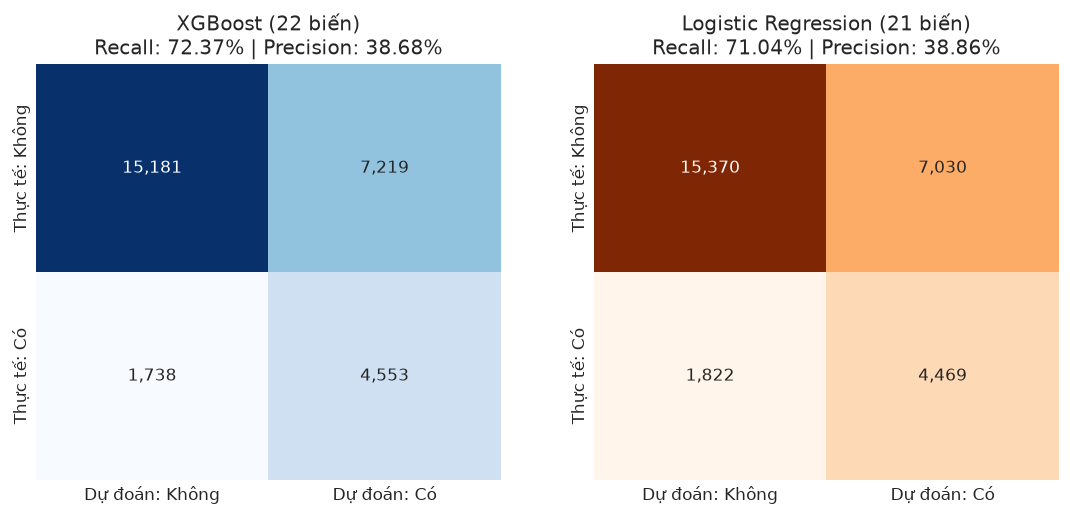

In [1]:
# Biểu đồ 13: Ma trận nhầm lẫn (Confusion Matrix) của XGBoost và Logistic Regression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm_xgb, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Dự đoán: Không', 'Dự đoán: Có'], yticklabels=['Thực tế: Không', 'Thực tế: Có'])
ax1.set_title(f"XGBoost (22 biến)
Recall: {recall_score(test_df[TARGET], xgb_test_preds)*100:.2f}% | Precision: {precision_score(test_df[TARGET], xgb_test_preds)*100:.2f}%")

sns.heatmap(cm_lr, annot=True, fmt=',d', cmap='Oranges', cbar=False, ax=ax2,
            xticklabels=['Dự đoán: Không', 'Dự đoán: Có'], yticklabels=['Thực tế: Không', 'Thực tế: Có'])
ax2.set_title(f"Logistic Regression (21 biến)
Recall: {recall_score(test_df[TARGET], lr_test_preds)*100:.2f}% | Precision: {precision_score(test_df[TARGET], lr_test_preds)*100:.2f}%")
plt.show()


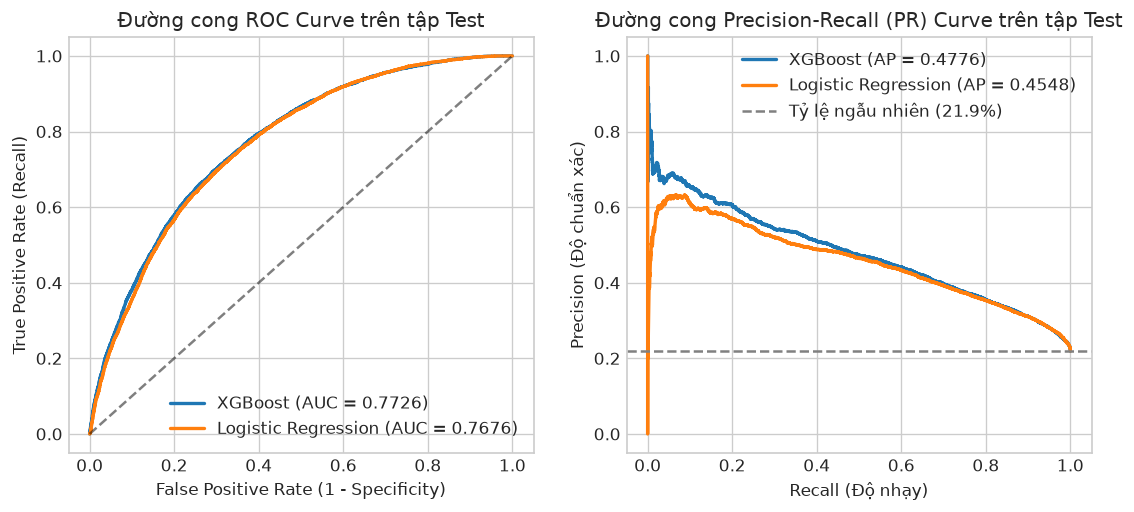

In [1]:
# Biểu đồ 14: Đường cong ROC Curve và Precision-Recall Curve trên tập Test độc lập
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr_xgb, tpr_xgb, _ = roc_curve(test_df[TARGET], xgb_test_probs)
fpr_lr, tpr_lr, _ = roc_curve(test_df[TARGET], lr_test_probs)
ax1.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(test_df[TARGET], xgb_test_probs):.4f})", color='#1f77b4', lw=2)
ax1.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(test_df[TARGET], lr_test_probs):.4f})", color='#ff7f0e', lw=2)
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_title("Đường cong ROC Curve trên tập Test")
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.legend(loc='lower right')

prec_xgb, rec_xgb, _ = precision_recall_curve(test_df[TARGET], xgb_test_probs)
prec_lr, rec_lr, _ = precision_recall_curve(test_df[TARGET], lr_test_probs)
ax2.plot(rec_xgb, prec_xgb, label=f"XGBoost (AP = {average_precision_score(test_df[TARGET], xgb_test_probs):.4f})", color='#1f77b4', lw=2)
ax2.plot(rec_lr, prec_lr, label=f"Logistic Regression (AP = {average_precision_score(test_df[TARGET], lr_test_probs):.4f})", color='#ff7f0e', lw=2)
baseline_pr = test_df[TARGET].mean()
ax2.axhline(baseline_pr, color='gray', linestyle='--', label=f"Tỷ lệ ngẫu nhiên ({baseline_pr*100:.1f}%)")
ax2.set_title("Đường cong Precision-Recall (PR) Curve trên tập Test")
ax2.set_xlabel("Recall (Độ nhạy)")
ax2.set_ylabel("Precision (Độ chuẩn xác)")
ax2.legend(loc='upper right')
plt.show()


In [1]:
# Bảng 38: Top 10 đặc trưng quan trọng nhất theo mô hình XGBoost
display(xgb_imp.head(10))


Đặc trưng,Mức độ quan trọng (%)
HighBP,24.879999
GenHlth,24.580000
HighBP_HighChol,19.500000
BMI,5.290000
DiffWalk,3.410000
HeartDiseaseorAttack,3.080000
HighChol,3.050000
HvyAlcoholConsump,3.030000
Sex,2.350000
Age,1.710000


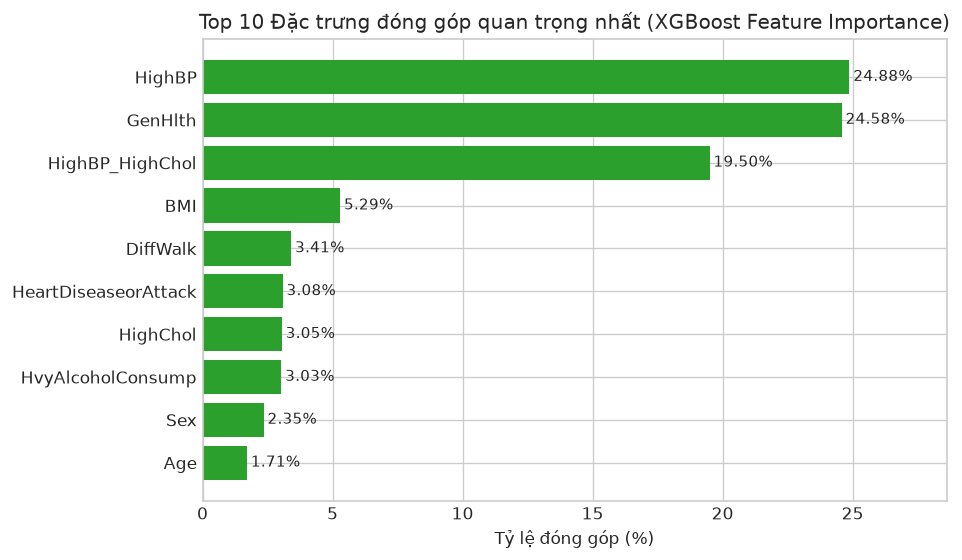

In [1]:
# Biểu đồ 15: Biểu đồ trực quan hóa Top 10 đặc trưng đóng góp lớn nhất (XGBoost)
fig, ax = plt.subplots(figsize=(8, 5))
top10_imp = xgb_imp.head(10).sort_values("Mức độ quan trọng (%)", ascending=True)
ax.barh(top10_imp['Đặc trưng'], top10_imp['Mức độ quan trọng (%)'], color='#2ca02c')
ax.set_title("Top 10 Đặc trưng đóng góp quan trọng nhất (XGBoost Feature Importance)")
ax.set_xlabel("Tỷ lệ đóng góp (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.2f}%", (p.get_width() + 0.15, p.get_y() + p.get_height()/2.), va='center', fontsize=9)
ax.set_xlim(0, top10_imp['Mức độ quan trọng (%)'].max() * 1.15)
plt.show()


# VIII. Kết luận, giới hạn và hướng nghiên cứu tiếp theo

## 8.1. Kết quả và mức cải thiện

Nhóm đã so sánh bộ 20 với bộ 16 biến trên bốn mô hình, sau đó thử từng biến tương tác trên Logistic Regression và XGBoost bằng cùng 5 fold. Nhóm chọn AP trung bình để quyết định qua từng lượt và chốt hai bộ trước khi đánh giá Test.

Khi đối chiếu trên cùng CV, nhóm ghi nhận AP và F1 tăng nhẹ so với baseline 20 biến:

| Mô hình | AP baseline | AP bộ cuối | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| **Logistic Regression** | 0.4578 | 0.4589 | 70.95% | 0.5045 | 0.8062 |
| **XGBoost** | 0.4746 | 0.4764 | 71.30% | 0.5081 | 0.8118 |

Nhóm chưa chứng minh khác biệt có ý nghĩa thống kê. Nhóm kết luận các biến tương tác chỉ đem lại mức cải thiện nhỏ trong thiết lập đã thử. Nhóm đánh giá các bộ cuối trên Test ở phần VII; nhóm không so sánh trực tiếp CV của baseline với Test của bộ cuối để khẳng định mức cải thiện.

**Trả lời câu hỏi nghiên cứu:** Nhóm quan sát trên toàn bộ dữ liệu sạch các liên hệ từng cặp với nhãn, nổi bật là GenHlth, BMI và HighBP trong heatmap Pearson. Nhóm chưa diễn giải các liên hệ này như nguyên nhân hoặc đóng góp độc lập. Trên Test, nhóm ghi nhận Logistic Regression có AP=0.4589, Precision=38.80%, Recall=70.95%, F1=50.45%; XGBoost có AP=0.4764, Precision=38.95%, Recall=71.30%, F1=50.81% tại ngưỡng 0.5.

Với XGBoost, nhóm nhận diện 4.485/6.290 hồ sơ nhãn 1, bỏ sót 1.805 hồ sơ và dự đoán nhãn 1 cho 7.030 hồ sơ nhãn 0. Nhóm cần nêu cả mức nhận diện và báo nhầm. Nếu chỉ dự đoán nhãn 0, nhóm đạt Accuracy=78.08% trên Test nhưng Recall nhãn 1 bằng 0; hai mô hình dùng trọng số lớp đạt Accuracy khoảng 69% cùng Recall khoảng 71%. Vì vậy, nhóm không dùng Accuracy riêng lẻ để kết luận mô hình tốt hơn.

## 8.2. Giả thuyết cho nghiên cứu tiếp theo: BMI cao và nhãn 0

Nhóm giữ BMI thập phân và các hồ sơ ngoài ngưỡng IQR trong nghiên cứu này. Nhóm đã kiểm tra phép chuyển đổi BMI, nhưng chưa xác minh độ chính xác của thông tin chiều cao/cân nặng tự khai hoặc đánh giá tác động riêng của các hồ sơ BMI rất cao lên kết quả mô hình.

Trong 143.454 hồ sơ sạch, nhóm ghi nhận các hồ sơ có BMI > 50 và nhãn 0, gồm các hồ sơ có BMI > 90; BMI lớn nhất trong nhóm này là 97.65. Nhãn 0 biểu thị câu trả lời DIABETE3=3, không phải xác nhận độc lập qua xét nghiệm.

Nhóm đặt giả thuyết rằng việc rà soát chất lượng dữ liệu ở các hồ sơ BMI cao có thể cung cấp thông tin cho nghiên cứu sau. Nhóm đề xuất quy tắc gắn cờ **`(BMI > 50) & (Diabetes_binary == 0)`** như một cách xác định hồ sơ cần kiểm tra. Nhóm chọn ngưỡng 50 để đề xuất rà soát, chưa xác nhận đó là ngưỡng phát hiện lỗi hoặc khẳng định các hồ sơ này gây ra mức cải thiện nhỏ của mô hình.

Nhóm chưa kết luận BMI cao đi kèm nhãn 0 là dữ liệu nhiễu hay nhãn sai. CDC trình bày BMI như chỉ số sàng lọc cần xem cùng thông tin sức khỏe khác; nhóm không suy ra tình trạng tiểu đường từ riêng BMI. Tham khảo [CDC — About BMI](https://www.cdc.gov/bmi/about/).

Nhóm chỉ nêu giả thuyết, không thực hiện gắn cờ, sửa nhãn, xóa hồ sơ hoặc fine-tuning trong dự án này. Nếu một nghiên cứu sau sử dụng cờ, nhóm chỉ dùng nó để rà soát vì công thức chứa nhãn; nhóm không đưa cờ vào đầu vào dự đoán. Việc đánh giá quy tắc mới cũng cần kế hoạch xác thực riêng, vì nhóm đã xem kết quả Test hiện tại.

## 8.3. Giới hạn nghiên cứu

Nhóm phân loại nhãn tự khai gộp tiền tiểu đường/tiểu đường trong mẫu khảo sát từ 60 tuổi trở lên. Nhóm đã loại 28.84% hồ sơ ở bước làm sạch và chưa dùng trọng số khảo sát; nhóm cần cân nhắc thiên lệch chọn mẫu. Nhóm chọn biến qua EDA và nhiều lượt CV trên cùng Train nên kết quả CV có thể lạc quan. Nhóm chưa thực hiện nested CV hoặc xác thực trên dữ liệu bên ngoài. Nhóm đã xem thống kê toàn mẫu trước khi chia dữ liệu; sau khi chia, nhóm chỉ dùng Train để chọn cấu hình và giữ chỉ số hiệu năng Test đến đánh giá cuối.

Nhóm chưa coi kết quả là bằng chứng chẩn đoán lâm sàng, dự báo phát bệnh tương lai hoặc thay thế quyết định của nhân viên y tế. Nhóm kết thúc dự án tại mục VIII, giữ nguyên dữ liệu, mô hình và kết quả đã báo cáo.

## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ biến đặc trưng và phần lớn quy trình xử lý ban đầu. Nhóm chọn người từ 60 tuổi trở lên trong báo cáo này, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và tài liệu y tế chuyên ngành dịch tễ học. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.